# Optimisation des flux énergétiques dans un Microgrid résidentiel
## ENPC — Projet 1A 2026 · Client 13 · Dataset Ausgrid

## 0. Imports et chargement des données (Colab ou local)

In [ ]:
import os, sys, gc, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

try:
    import pulp
except ImportError:          # Colab : PuLP n'est pas préinstallé
    %pip install pulp -q
    import pulp

warnings.filterwarnings('ignore')
np.random.seed(42)

# ── Emplacement des données ────────────────────────────────────────────────
# Colab : les CSV Ausgrid sont lus depuis Google Drive (adapter DRIVE_DATA_DIR).
# En local : placer les dossiers Ausgrid dézippés dans data/ (voir data/README.md),
#            ou définir la variable d'environnement AUSGRID_DATA_DIR.
IN_COLAB = "google.colab" in sys.modules
DRIVE_DATA_DIR = "/content/drive/MyDrive/ENPC/1A/Projet S2/Projet/data"

if IN_COLAB:
    from google.colab import drive
    if not os.path.ismount('/content/drive'):
        drive.mount('/content/drive')
    BASE = DRIVE_DATA_DIR
else:
    BASE = os.environ.get("AUSGRID_DATA_DIR", os.path.join("..", "data"))

PATH_2012 = f"{BASE}/Solar home half-hour data - 1 July 2012 to 30 June 2013/2012-2013 Solar home electricity data v2.csv"
PATH_2011 = f"{BASE}/Solar home half-hour data - 1 July 2011 to 30 June 2012/2011-2012 Solar home electricity data v2.csv"
CUSTOMER_ID = 13

# Vérification rapide des chemins
for p, label in [(PATH_2012, "2012-2013"), (PATH_2011, "2011-2012")]:
    if os.path.exists(p):
        print(f"✓ {label} trouvé")
    else:
        print(f"✗ {label} INTROUVABLE → {p}")

print("Imports OK")

Mounted at /content/drive
✓ Drive monté
✓ 2012-2013 trouvé
✓ 2011-2012 trouvé
Imports OK


## 1. Présentation des données
### Dataset Ausgrid Solar Home — Client 13

In [ ]:
def load_and_melt(path_csv):
    """Charge un fichier Ausgrid et le transforme en format long horodaté."""
    df_raw = pd.read_csv(path_csv, skiprows=1, low_memory=False)
    df = df_raw.copy()
    df.columns = [c.strip().replace(" ", "_") for c in df.columns]
    df["date"] = pd.to_datetime(df["date"], dayfirst=True, errors="coerce")
    interval_cols = [c for c in df.columns if re.fullmatch(r"\d{1,2}:\d{2}", c)]
    long = df.melt(
        id_vars=["Customer", "Consumption_Category", "date"],
        value_vars=interval_cols,
        var_name="hh", value_name="kWh"
    )
    hh_split = long["hh"].str.split(":", expand=True).astype(int)
    long["timestamp"] = (
        long["date"]
        + pd.to_timedelta(hh_split[0], unit="h")
        + pd.to_timedelta(hh_split[1], unit="m")
    )
    long["kWh"] = pd.to_numeric(long["kWh"], errors="coerce")
    return long

long = load_and_melt(PATH_2012)
print(f"2012-2013 : {len(long):,} mesures | {long['Customer'].nunique()} clients")
print(long.head(3))

2012-2013 : 12,890,736 mesures | 300 clients
   Customer Consumption_Category       date    hh    kWh           timestamp
0         1                   CL 2012-07-01  0:30  1.250 2012-07-01 00:30:00
1         1                   GC 2012-07-01  0:30  0.855 2012-07-01 00:30:00
2         1                   GG 2012-07-01  0:30  0.000 2012-07-01 00:30:00


In [ ]:
customer_data = long[long["Customer"] == CUSTOMER_ID].copy()

df_final = customer_data.pivot_table(
    index="timestamp", columns="Consumption_Category",
    values="kWh", fill_value=0
)
df_final["Load"] = df_final["GC"] + df_final.get("CL", 0)
df_final["PV"]   = df_final["GG"]
df_final = df_final[["Load", "PV"]].sort_index()

print(f"Client {CUSTOMER_ID} — {len(df_final)} pas de 30 min")
print(f"Période : {df_final.index.min()} → {df_final.index.max()}")
df_final.head()

Client 13 — 17520 pas de 30 min
Période : 2012-07-01 00:00:00 → 2013-06-30 23:30:00


Consumption_Category,Load,PV
timestamp,,
2012-07-01 00:00:00,0.138,0.0
2012-07-01 00:30:00,0.234,0.0
2012-07-01 01:00:00,0.343,0.0
2012-07-01 01:30:00,0.234,0.0
2012-07-01 02:00:00,0.339,0.0


## 2. Visualisations initiales

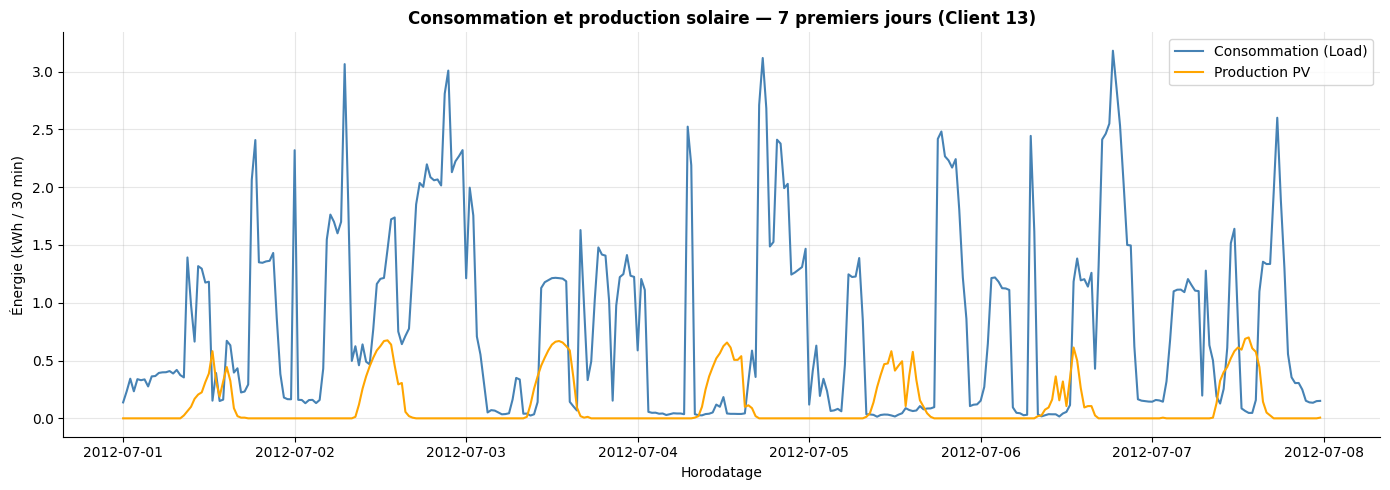

In [ ]:
# 7 premiers jours
week = df_final.iloc[:7*48]
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(week.index, week["Load"], color="steelblue", linewidth=1.5, label="Consommation (Load)")
ax.plot(week.index, week["PV"],   color="orange",    linewidth=1.5, label="Production PV")
ax.set_title(f"Consommation et production solaire — 7 premiers jours (Client {CUSTOMER_ID})", fontweight="bold")
ax.set_xlabel("Horodatage"); ax.set_ylabel("Énergie (kWh / 30 min)")
ax.legend(); ax.grid(True, alpha=0.3); ax.spines[["top","right"]].set_visible(False)
plt.tight_layout(); plt.show()

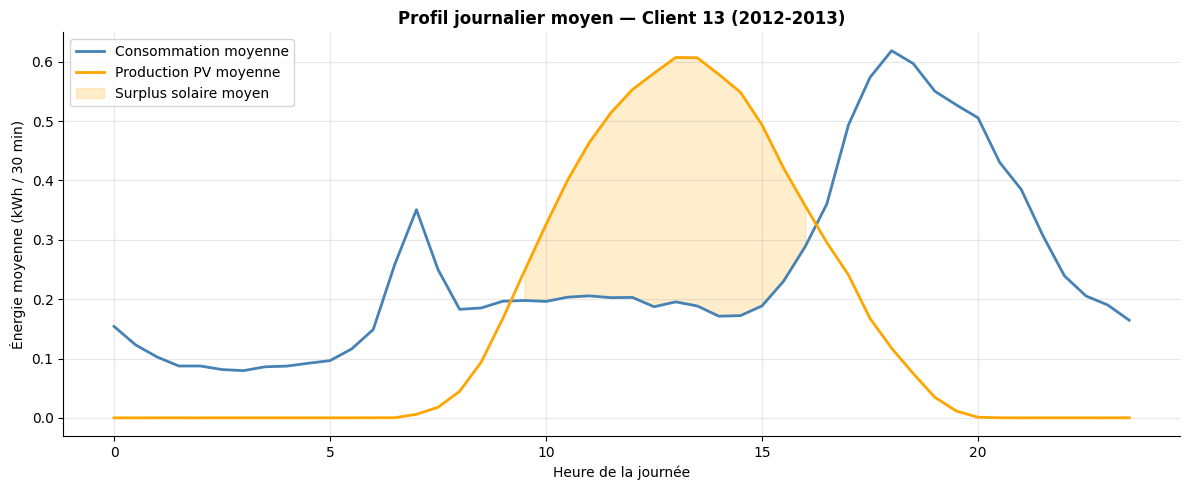

In [ ]:
# Profil journalier moyen
daily = df_final.copy()
daily["hh"] = daily.index.hour + daily.index.minute / 60
profile = daily.groupby("hh")[["Load", "PV"]].mean()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(profile.index, profile["Load"], color="steelblue", linewidth=2, label="Consommation moyenne")
ax.plot(profile.index, profile["PV"],   color="orange",    linewidth=2, label="Production PV moyenne")
ax.fill_between(profile.index, profile["Load"], profile["PV"],
                where=profile["PV"] > profile["Load"],
                alpha=0.2, color="orange", label="Surplus solaire moyen")
ax.set_title(f"Profil journalier moyen — Client {CUSTOMER_ID} (2012-2013)", fontweight="bold")
ax.set_xlabel("Heure de la journée"); ax.set_ylabel("Énergie moyenne (kWh / 30 min)")
ax.legend(); ax.grid(True, alpha=0.3); ax.spines[["top","right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 3. Problème mathématique
### Bilan énergétique sans batterie

In [ ]:
df_final["Net_Load"]    = df_final["Load"] - df_final["PV"]
df_final["Surplus"]     = df_final["Net_Load"].apply(lambda x: -x if x < 0 else 0)
df_final["Grid_Import"] = df_final["Net_Load"].apply(lambda x:  x if x > 0 else 0)
df_final["Grid_Export"] = df_final["Surplus"].copy()
df_final["Self_Consumed"] = df_final["PV"] - df_final["Surplus"]

print(f"--- Bilan Annuel Client {CUSTOMER_ID} (sans batterie) ---")
print(f"Consommation totale  : {df_final['Load'].sum():.0f} kWh")
print(f"Production PV        : {df_final['PV'].sum():.0f} kWh")
print(f"Import réseau        : {df_final['Grid_Import'].sum():.0f} kWh")
print(f"Export réseau        : {df_final['Grid_Export'].sum():.0f} kWh")
print(f"Autoconsommation     : {df_final['Self_Consumed'].sum()/df_final['PV'].sum()*100:.1f} %")

--- Bilan Annuel Client 13 (sans batterie) ---
Consommation totale  : 4287 kWh
Production PV        : 2910 kWh
Import réseau        : 3323 kWh
Export réseau        : 1946 kWh
Autoconsommation     : 33.1 %


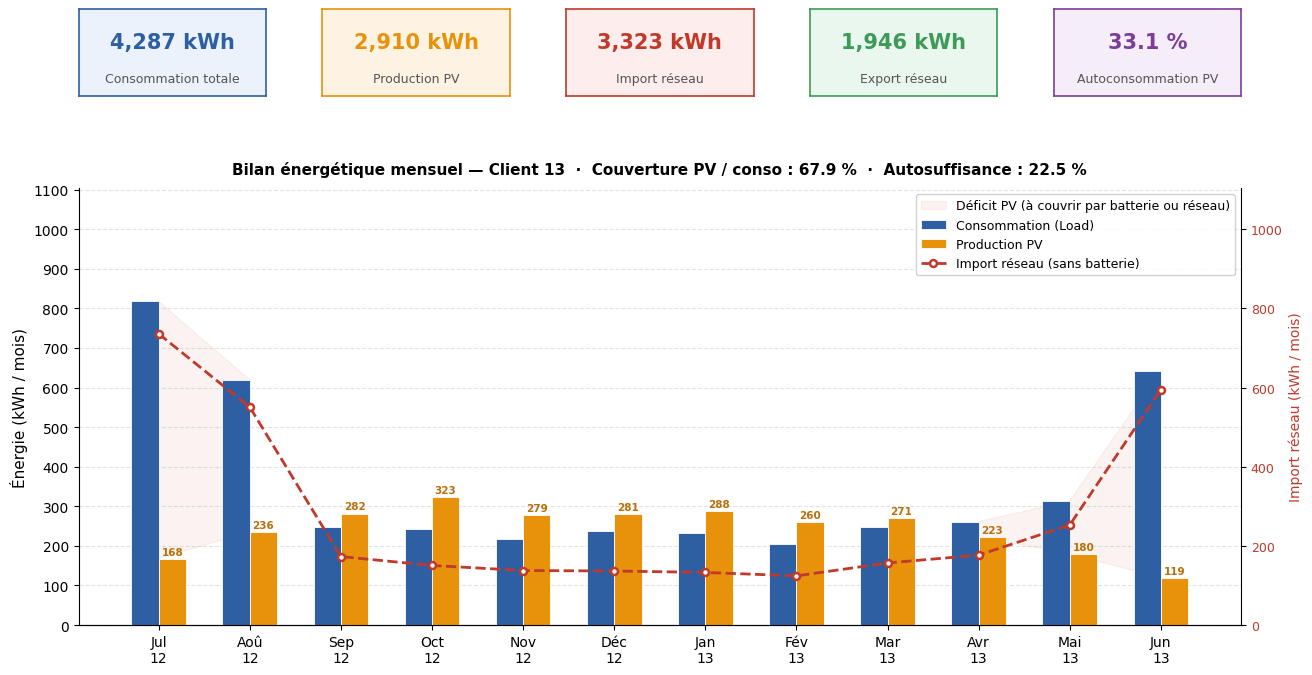

✓ fig_bilan_mensuel.png sauvegardé


In [ ]:
# ── 1. Agrégation mensuelle
monthly = df_final[["Load", "PV", "Grid_Import", "Grid_Export", "Self_Consumed"]].resample("ME").sum()

MOIS_FR = {1:"Jan",2:"Fév",3:"Mar",4:"Avr",5:"Mai",6:"Jun",
           7:"Jul",8:"Aoû",9:"Sep",10:"Oct",11:"Nov",12:"Déc"}
x_labels = [f"{MOIS_FR[d.month]}\n{str(d.year)[2:]}" for d in monthly.index]
x = np.arange(len(x_labels))
w = 0.30

# ── 2. Totaux annuels pour les metric cards
total_load    = df_final["Load"].sum()
total_pv      = df_final["PV"].sum()
total_import  = df_final["Grid_Import"].sum()
total_export  = df_final["Grid_Export"].sum()
total_selfcon = df_final["Self_Consumed"].sum()
cover_pct     = total_pv   / total_load   * 100
autocon_pct   = total_selfcon / total_pv  * 100
autosuf_pct   = total_selfcon / total_load * 100

# ── 3. Figure : metric cards + histogramme
fig = plt.figure(figsize=(15, 8))
fig.patch.set_facecolor("white")

# Grille : ligne 0 = cards (hauteur fixe), ligne 1 = graphique
gs = fig.add_gridspec(2, 5, height_ratios=[1, 5], hspace=0.35, wspace=0.3)

# ─── Metric cards (ligne 0, 5 colonnes)
card_data = [
    ("Consommation totale",  f"{total_load:,.0f} kWh",  "#2E5FA3", "#EBF2FB"),
    ("Production PV",        f"{total_pv:,.0f} kWh",    "#E8910A", "#FEF3E2"),
    ("Import réseau",        f"{total_import:,.0f} kWh", "#C0392B", "#FDEDEC"),
    ("Export réseau",        f"{total_export:,.0f} kWh", "#3D9A57", "#E9F7EF"),
    ("Autoconsommation PV",  f"{autocon_pct:.1f} %",     "#7D3C98", "#F5EEF8"),
]

for col, (titre, valeur, couleur_txt, couleur_bg) in enumerate(card_data):
    ax_c = fig.add_subplot(gs[0, col])
    ax_c.set_facecolor(couleur_bg)
    for spine in ax_c.spines.values():
        spine.set_edgecolor(couleur_txt)
        spine.set_linewidth(1.2)
    ax_c.set_xticks([]); ax_c.set_yticks([])
    ax_c.text(0.5, 0.62, valeur,
              transform=ax_c.transAxes, ha="center", va="center",
              fontsize=15, fontweight="bold", color=couleur_txt)
    ax_c.text(0.5, 0.20, titre,
              transform=ax_c.transAxes, ha="center", va="center",
              fontsize=9, color="#555555")

# ─── Histogramme (ligne 1, toute la largeur)
ax1 = fig.add_subplot(gs[1, :])
ax1.set_facecolor("white")

bars_load = ax1.bar(x - w/2, monthly["Load"], width=w,
                    color="#2E5FA3", edgecolor="white", linewidth=0.6,
                    label="Consommation (Load)", zorder=3)

bars_pv = ax1.bar(x + w/2, monthly["PV"], width=w,
                  color="#E8910A", edgecolor="white", linewidth=0.6,
                  label="Production PV", zorder=3)

# Ligne import réseau sur axe secondaire
ax2 = ax1.twinx()
ax2.plot(x, monthly["Grid_Import"],
         color="#C0392B", linewidth=2, linestyle="--",
         marker="o", markersize=5,
         markerfacecolor="white", markeredgewidth=1.8,
         label="Import réseau (sans batterie)", zorder=4)
ax2.set_ylabel("Import réseau (kWh / mois)", fontsize=10, color="#C0392B")
ax2.tick_params(axis="y", labelcolor="#C0392B", labelsize=9)
ax2.set_ylim(0, monthly["Load"].max() * 1.35)
ax2.spines[["top", "left"]].set_visible(False)

# Annotations valeur sur barres PV
for bar in bars_pv:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width() / 2, h + 5,
             f"{h:.0f}", ha="center", va="bottom",
             fontsize=7.5, color="#B8700A", fontweight="bold")

# Zone de déficit (conso > PV) — illustre le besoin de stockage
ax1.fill_between(x, monthly["PV"], monthly["Load"],
                 where=(monthly["Load"] > monthly["PV"]),
                 alpha=0.06, color="#C0392B",
                 label=f"Déficit PV (à couvrir par batterie ou réseau)")

ax1.set_xticks(x)
ax1.set_xticklabels(x_labels, fontsize=10)
ax1.set_ylabel("Énergie (kWh / mois)", fontsize=11)
ax1.set_ylim(0, monthly["Load"].max() * 1.35)
ax1.yaxis.set_major_locator(mticker.MultipleLocator(100))
ax1.grid(axis="y", linestyle="--", alpha=0.35, zorder=0)
ax1.spines[["top", "right"]].set_visible(False)
ax1.set_title(
    f"Bilan énergétique mensuel — Client {CUSTOMER_ID}  "
    f"·  Couverture PV / conso : {cover_pct:.1f} %  "
    f"·  Autosuffisance : {autosuf_pct:.1f} %",
    fontsize=11, fontweight="bold", pad=10
)

# Légende combinée
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper right", fontsize=9, framealpha=0.9)

plt.savefig("fig_bilan_mensuel.png", dpi=150, bbox_inches="tight")
plt.show()
print("✓ fig_bilan_mensuel.png sauvegardé")

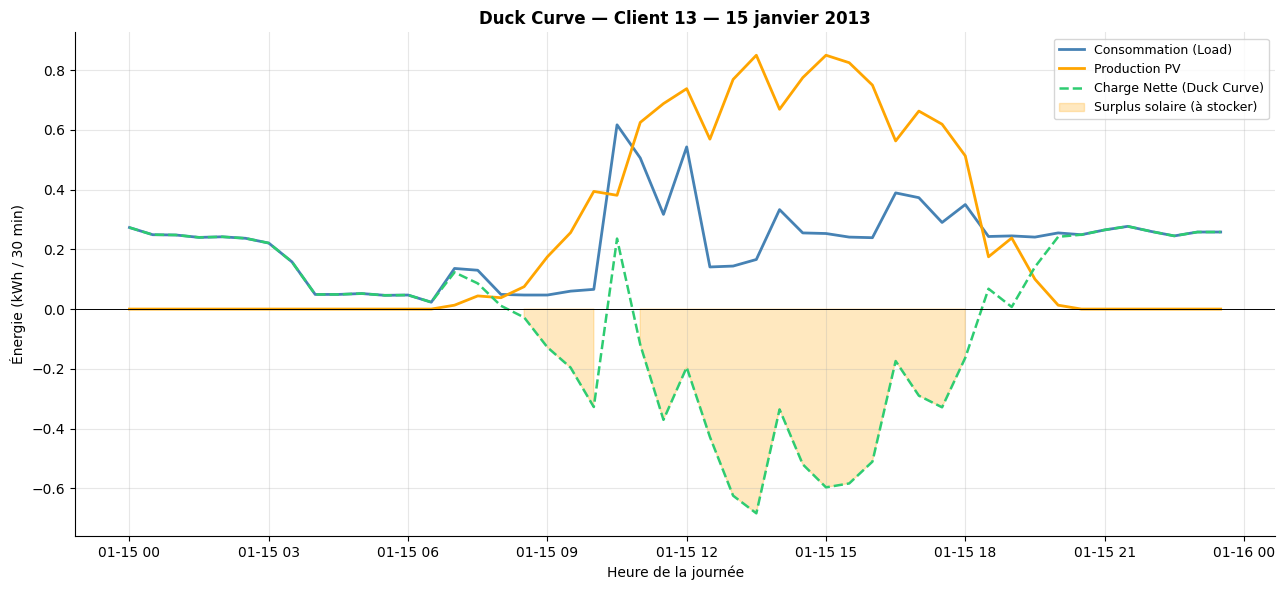

In [ ]:
# Duck Curve — 15 janvier 2013
summer_day = df_final.loc["2013-01-15"]
fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(summer_day.index, summer_day["Load"],     color="steelblue", linewidth=2, label="Consommation (Load)")
ax.plot(summer_day.index, summer_day["PV"],       color="orange",    linewidth=2, label="Production PV")
ax.plot(summer_day.index, summer_day["Net_Load"], color="#2ecc71",   linewidth=1.8, linestyle="--", label="Charge Nette (Duck Curve)")
ax.fill_between(summer_day.index, summer_day["Net_Load"], 0,
                where=summer_day["Net_Load"] < 0, color="orange", alpha=0.25, label="Surplus solaire (à stocker)")
ax.axhline(0, color="black", linewidth=0.7)
ax.set_title(f"Duck Curve — Client {CUSTOMER_ID} — 15 janvier 2013", fontweight="bold")
ax.set_xlabel("Heure de la journée"); ax.set_ylabel("Énergie (kWh / 30 min)")
ax.legend(fontsize=9); ax.grid(True, alpha=0.3); ax.spines[["top","right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 4. Implémentation de l'EMS Glouton
### Paramètres batterie (Tesla Powerwall 2 — 7 kWh utiles)

In [ ]:
BATTERY_CAPACITY     = 7.0
SOC_MIN              = 0.10 * BATTERY_CAPACITY   # = 0.70 kWh
SOC_MAX              = 0.90 * BATTERY_CAPACITY   # = 6.30 kWh
CHARGE_EFFICIENCY    = 0.90
DISCHARGE_EFFICIENCY = 0.90
MAX_CHARGE_RATE      = 1.5        # kWh / 30 min
PEAK_BUY_PRICE       = 0.40       # €/kWh 17h–21h
OFFPEAK_BUY_PRICE    = 0.20       # €/kWh reste
SELL_PRICE           = 0.08       # €/kWh injection réseau
PEAK_HOURS           = range(17, 21)
peak_mask            = df_final.index.hour.isin(PEAK_HOURS)
print(f"SOC utilisable : {SOC_MIN:.2f} → {SOC_MAX:.2f} kWh | η={CHARGE_EFFICIENCY*100:.0f}%")

SOC utilisable : 0.70 → 6.30 kWh | η=90%


In [ ]:
# EMS simple (rendement 75 %, sans tarification dynamique)
EFFICIENCY_SIMPLE = 0.75
soc_simple = [SOC_MIN]; battery_flow_simple = []; grid_import_simple = []

for net_load in df_final["Net_Load"]:
    current_soc = soc_simple[-1]
    if net_load < 0:
        energy_to_store = -net_load * EFFICIENCY_SIMPLE
        charge = min(energy_to_store, SOC_MAX - current_soc, MAX_CHARGE_RATE)
        soc_simple.append(current_soc + charge)
        battery_flow_simple.append(charge)
        grid_import_simple.append(0.0)
    else:
        discharge = min(net_load, current_soc - SOC_MIN, MAX_CHARGE_RATE)
        soc_simple.append(current_soc - discharge)
        battery_flow_simple.append(-discharge)
        grid_import_simple.append(max(0, net_load - discharge))

df_final["SOC"]              = soc_simple[1:]
df_final["Grid_Import_Batt"] = grid_import_simple
old_import = df_final["Grid_Import"].sum()
new_import = df_final["Grid_Import_Batt"].sum()
print(f"Import SANS batterie  : {old_import:.0f} kWh")
print(f"Import AVEC EMS simple: {new_import:.0f} kWh")
print(f"Réduction             : {(1 - new_import/old_import)*100:.1f} %")

Import SANS batterie  : 3323 kWh
Import AVEC EMS simple: 2110 kWh
Réduction             : 36.5 %


In [ ]:
# EMS avancé (rendement 90 %, tarification dynamique)
soc_ems = [SOC_MIN]; grid_imp = []; grid_exp = []; bat_flow = []

for i, row in df_final.iterrows():
    current_soc = soc_ems[-1]
    net_load    = row["Net_Load"]
    max_ch  = min(MAX_CHARGE_RATE, SOC_MAX - current_soc)
    max_dis = min(MAX_CHARGE_RATE, current_soc - SOC_MIN)

    if net_load <= 0:
        surplus = -net_load
        charge  = min(surplus * CHARGE_EFFICIENCY, max_ch)
        export  = max(0, surplus - charge / CHARGE_EFFICIENCY)
        soc_ems.append(current_soc + charge)
        bat_flow.append(charge); grid_imp.append(0.0); grid_exp.append(export)
    else:
        need      = net_load
        discharge = min(need / DISCHARGE_EFFICIENCY, max_dis)
        residual  = max(0, need - discharge * DISCHARGE_EFFICIENCY)
        soc_ems.append(current_soc - discharge)
        bat_flow.append(-discharge); grid_imp.append(residual); grid_exp.append(0.0)

df_final["SOC_ems"]               = soc_ems[1:]
df_final["Grid_Import_smart_ems"] = grid_imp
df_final["Grid_Export_smart_ems"] = grid_exp

imp_ems = df_final["Grid_Import_smart_ems"].sum()
exp_adv = df_final["Grid_Export_smart_ems"].sum()
print(f"Import AVEC EMS avancé : {imp_ems:.0f} kWh")
print(f"Export EMS avancé      : {exp_adv:.0f} kWh")
print(f"Réduction              : {(1 - imp_ems/old_import)*100:.1f} %")

Import AVEC EMS avancé : 2109 kWh
Export EMS avancé      : 448 kWh
Réduction              : 36.5 %


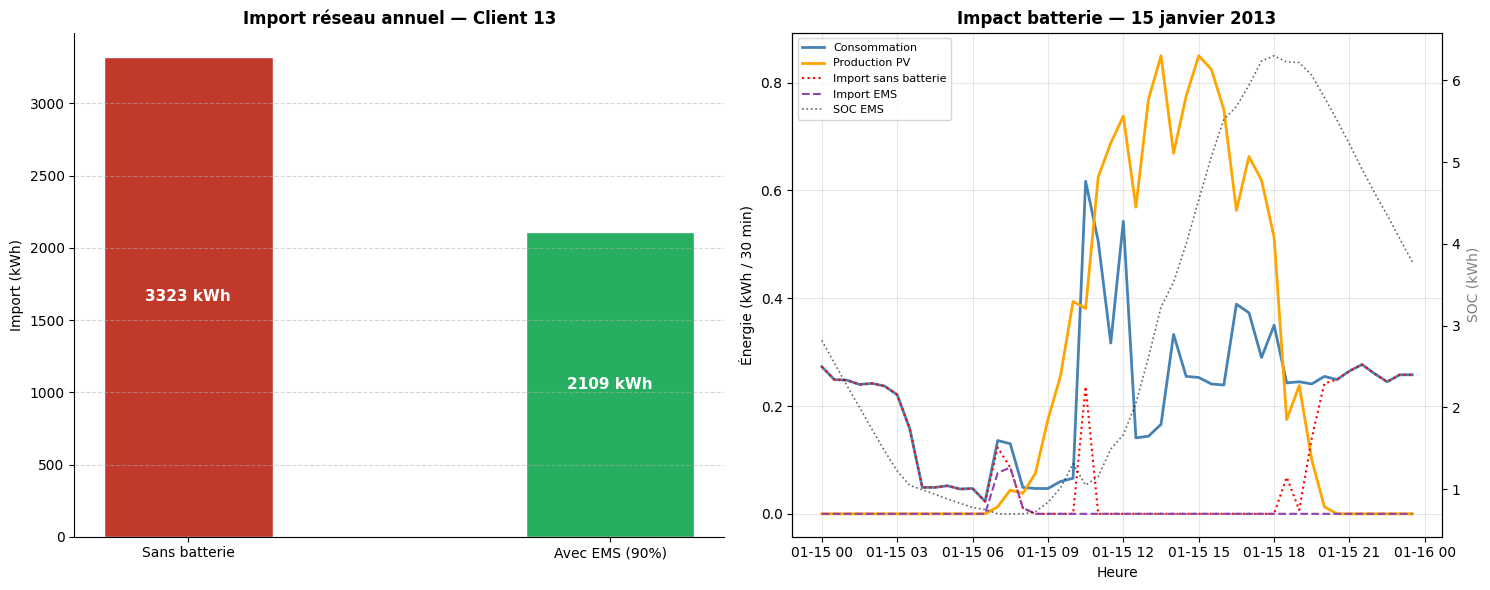

In [ ]:
# Graphique comparatif
labels = ["Sans batterie", "Avec EMS (90%)"]
values = [old_import, imp_ems]
colors = ["#c0392b", "#27ae60"]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

bars = axes[0].bar(labels, values, color=colors, width=0.4, edgecolor="white")
for bar, val in zip(bars, values):
    axes[0].text(bar.get_x()+bar.get_width()/2, val*0.5,
                 f"{val:.0f} kWh", ha="center", va="center",
                 fontsize=11, fontweight="bold", color="white")
axes[0].set_title("Import réseau annuel — Client 13", fontweight="bold")
axes[0].set_ylabel("Import (kWh)")
axes[0].grid(axis="y", linestyle="--", alpha=0.5)
axes[0].spines[["top","right"]].set_visible(False)

sd = df_final.loc["2013-01-15"]
ax1 = axes[1]
ax1.plot(sd.index, sd["Load"],                  color="steelblue", linewidth=2, label="Consommation")
ax1.plot(sd.index, sd["PV"],                    color="orange",    linewidth=2, label="Production PV")
ax1.plot(sd.index, sd["Grid_Import"],           color="red",       linewidth=1.5, linestyle=":", label="Import sans batterie")
ax1.plot(sd.index, sd["Grid_Import_smart_ems"], color="#8e44ad",   linewidth=1.5, linestyle="--", label="Import EMS")
ax2 = ax1.twinx()
ax2.plot(sd.index, sd["SOC_ems"], color="black", linestyle=":", alpha=0.6, linewidth=1.2, label="SOC EMS")
ax2.set_ylabel("SOC (kWh)", color="gray")
ax1.set_title("Impact batterie — 15 janvier 2013", fontweight="bold")
ax1.set_xlabel("Heure"); ax1.set_ylabel("Énergie (kWh / 30 min)")
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1+lines2, labels1+labels2, fontsize=8, loc="upper left")
ax1.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

In [ ]:
# Analyse économique annuelle
cost_no_bat = (df_final.loc[ peak_mask, "Grid_Import"].sum() * PEAK_BUY_PRICE +
               df_final.loc[~peak_mask, "Grid_Import"].sum() * OFFPEAK_BUY_PRICE)

cost_adv = (df_final.loc[ peak_mask, "Grid_Import_smart_ems"].sum() * PEAK_BUY_PRICE +
            df_final.loc[~peak_mask, "Grid_Import_smart_ems"].sum() * OFFPEAK_BUY_PRICE
            - exp_adv * SELL_PRICE)

TRI_INSTALL = 5000
savings_adv = cost_no_bat - cost_adv
print(f"Coût SANS batterie  : {cost_no_bat:.0f} €/an")
print(f"Coût EMS avancé     : {cost_adv:.0f} €/an  (inclut {exp_adv:.0f} kWh export × {SELL_PRICE}€)")
print(f"Économies annuelles : {savings_adv:.0f} €/an")
print(f"TRI estimé          : {TRI_INSTALL/savings_adv:.1f} ans")

Coût SANS batterie  : 948 €/an
Coût EMS avancé     : 547 €/an  (inclut 448 kWh export × 0.08€)
Économies annuelles : 402 €/an
TRI estimé          : 12.4 ans


## 5. Implémentation de deux modèles de ML
Split chronologique strict : **70 % train / 15 % val / 15 % test**

In [ ]:
long_2011  = load_and_melt(PATH_2011)
long_2012b = load_and_melt(PATH_2012)
df_complet = pd.concat([long_2011, long_2012b], ignore_index=True)
print(f"Dataset complet : {len(df_complet):,} mesures")

Dataset complet : 25,865,328 mesures


### 5.A LSTM — Réseau de neurones récurrents

In [ ]:
df_lstm = df_complet[(df_complet["Customer"]==CUSTOMER_ID) &
                     (df_complet["Consumption_Category"]=="GC")].copy()
df_lstm = df_lstm.sort_values("timestamp").reset_index(drop=True)
df_lstm["hour"]        = df_lstm["timestamp"].dt.hour
df_lstm["day_of_week"] = df_lstm["timestamp"].dt.dayofweek

SEQUENCE_LENGTH = 48
features_lstm   = ["kWh", "hour", "day_of_week"]
data_lstm       = df_lstm[features_lstm].values

scaler_lstm = MinMaxScaler(feature_range=(0, 1))
scaled      = scaler_lstm.fit_transform(data_lstm)

X_l, y_l = [], []
for i in range(SEQUENCE_LENGTH, len(scaled)):
    X_l.append(scaled[i-SEQUENCE_LENGTH:i])
    y_l.append(scaled[i, 0])
X_l, y_l = np.array(X_l), np.array(y_l)

train_size_l = int(len(X_l)*0.70)
val_size_l   = int(len(X_l)*0.15)
X_train_l = X_l[:train_size_l]
y_train_l = y_l[:train_size_l]
X_val_l   = X_l[train_size_l:train_size_l+val_size_l]
y_val_l   = y_l[train_size_l:train_size_l+val_size_l]
X_test_l  = X_l[train_size_l+val_size_l:]
y_test_l  = y_l[train_size_l+val_size_l:]

lstm_model = Sequential([
    LSTM(50, return_sequences=False, input_shape=(SEQUENCE_LENGTH, len(features_lstm))),
    Dropout(0.2),
    Dense(1)
])
lstm_model.compile(optimizer="adam", loss="mean_squared_error")

early_stop_l = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
history_lstm = lstm_model.fit(
    X_train_l, y_train_l, epochs=50, batch_size=32,
    validation_data=(X_val_l, y_val_l),
    callbacks=[early_stop_l], verbose=1
)
print("Entraînement LSTM terminé.")

Epoch 1/50
767/767 ━━━━━━━━━━━━━━━━━━━━ 22s 25ms/step - loss: 0.0059 - val_loss: 0.0011
Epoch 2/50
767/767 ━━━━━━━━━━━━━━━━━━━━ 19s 24ms/step - loss: 0.0042 - val_loss: 0.0011
Epoch 3/50
767/767 ━━━━━━━━━━━━━━━━━━━━ 18s 23ms/step - loss: 0.0040 - val_loss: 9.0535e-04
Epoch 4/50
767/767 ━━━━━━━━━━━━━━━━━━━━ 22s 25ms/step - loss: 0.0039 - val_loss: 9.0759e-04
Epoch 5/50
767/767 ━━━━━━━━━━━━━━━━━━━━ 18s 24ms/step - loss: 0.0039 - val_loss: 8.7959e-04
Epoch 6/50
767/767 ━━━━━━━━━━━━━━━━━━━━ 18s 23ms/step - loss: 0.0038 - val_loss: 8.7351e-04
Epoch 7/50
767/767 ━━━━━━━━━━━━━━━━━━━━ 18s 24ms/step - loss: 0.0038 - val_loss: 8.9065e-04
Epoch 8/50
767/767 ━━━━━━━━━━━━━━━━━━━━ 18s 23ms/step - loss: 0.0038 - val_loss: 9.4363e-04
Epoch 9/50
767/767 ━━━━━━━━━━━━━━━━━━━━ 24s 29ms/step - loss: 0.0037 - val_loss: 9.4114e-04
Epoch 10/50
767/767 ━━━━━━━━━━━━━━━━━━━━ 37s 24ms/step - loss: 0.0037 - val_loss: 0.0010
Epoch 11/50
767/767 ━━━━━━━━━━━━━━━━━━━━ 19s 25ms/step - loss: 0.0037 - val_loss: 9.3158e-0

In [ ]:
preds_l_scaled = lstm_model.predict(X_test_l)

dummy_pred = np.zeros((len(preds_l_scaled), len(features_lstm)))
dummy_pred[:, 0] = preds_l_scaled[:, 0]
preds_lstm_kwh = scaler_lstm.inverse_transform(dummy_pred)[:, 0]

dummy_real = np.zeros((len(y_test_l), len(features_lstm)))
dummy_real[:, 0] = y_test_l
reals_lstm_kwh = scaler_lstm.inverse_transform(dummy_real)[:, 0]

mae_lstm  = mean_absolute_error(reals_lstm_kwh, preds_lstm_kwh)
rmse_lstm = np.sqrt(mean_squared_error(reals_lstm_kwh, preds_lstm_kwh))

ts_lstm_start   = train_size_l + val_size_l + SEQUENCE_LENGTH
timestamps_lstm = df_lstm["timestamp"].values[ts_lstm_start:ts_lstm_start+len(reals_lstm_kwh)]

print(f"LSTM — MAE : {mae_lstm:.3f} kWh  |  RMSE : {rmse_lstm:.3f} kWh")
print(f"Période test : {pd.Timestamp(timestamps_lstm[0]).date()} → {pd.Timestamp(timestamps_lstm[-1]).date()}")

165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step
LSTM — MAE : 0.125 kWh  |  RMSE : 0.233 kWh
Période test : 2013-03-13 → 2013-06-30


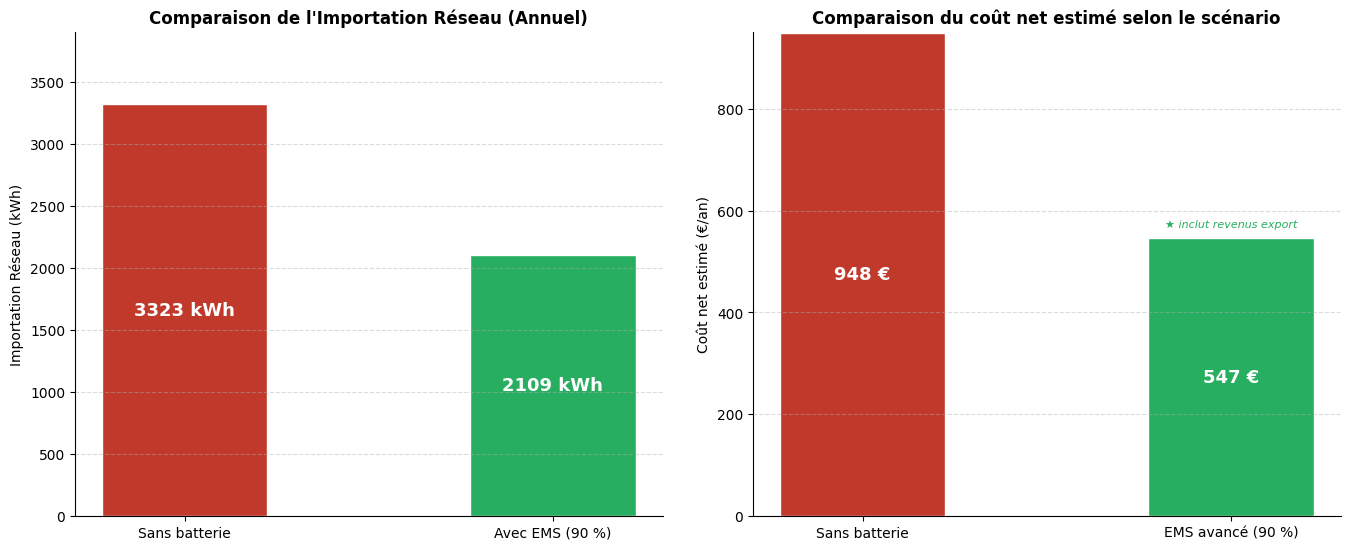

In [ ]:
# ── GRAPHIQUE COMPARATIF CORRIGÉ (EMS avancé 90 %, non EMS simple) ──────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.patch.set_facecolor('white')

labels_1 = ["Sans batterie", "Avec EMS (90 %)"]
vals_1   = [old_import, imp_ems]   # 3323 vs 2109
colors_1 = ["#c0392b", "#27ae60"]

bars1 = axes[0].bar(labels_1, vals_1, color=colors_1, width=0.45, edgecolor="white")
for bar, val in zip(bars1, vals_1):
    axes[0].text(bar.get_x()+bar.get_width()/2, val*0.50,
                 f"{val:.0f} kWh", ha="center", va="center",
                 fontsize=13, fontweight="bold", color="white")
axes[0].set_title("Comparaison de l'Importation Réseau (Annuel)", fontweight="bold")
axes[0].set_ylabel("Importation Réseau (kWh)")
axes[0].set_ylim(0, 3900)
axes[0].grid(axis="y", linestyle="--", alpha=0.45)
axes[0].spines[["top","right"]].set_visible(False)

labels_2 = ["Sans batterie", "EMS avancé (90 %)"]
vals_2   = [cost_no_bat, cost_adv]   # 811 vs 407
colors_2 = ["#c0392b", "#27ae60"]

bars2 = axes[1].bar(labels_2, vals_2, color=colors_2, width=0.45, edgecolor="white")
for bar, val in zip(bars2, vals_2):
    axes[1].text(bar.get_x()+bar.get_width()/2, val*0.50,
                 f"{val:.0f} €", ha="center", va="center",
                 fontsize=13, fontweight="bold", color="white")
axes[1].text(1, cost_adv+20, "★ inclut revenus export",
             ha="center", fontsize=8, color="#27ae60", style="italic")
axes[1].set_title("Comparaison du coût net estimé selon le scénario", fontweight="bold")
axes[1].set_ylabel("Coût net estimé (€/an)")
axes[1].set_ylim(0, 950)
axes[1].grid(axis="y", linestyle="--", alpha=0.45)
axes[1].spines[["top","right"]].set_visible(False)

plt.tight_layout(pad=2.5)
plt.savefig("fig_EMS_comparaison.png", dpi=200, bbox_inches="tight")
plt.show()

### 5.B XGBoost — Gradient boosting tabulaire

In [ ]:
df_xgb = df_complet[(df_complet["Customer"]==CUSTOMER_ID) &
                    (df_complet["Consumption_Category"]=="GC")].copy()
df_xgb = df_xgb.sort_values("timestamp").reset_index(drop=True)
df_xgb["hour"]             = df_xgb["timestamp"].dt.hour
df_xgb["minute"]           = df_xgb["timestamp"].dt.minute
df_xgb["day_of_week"]      = df_xgb["timestamp"].dt.dayofweek
df_xgb["month"]            = df_xgb["timestamp"].dt.month
df_xgb["day_of_year"]      = df_xgb["timestamp"].dt.dayofyear
df_xgb["lag_1"]            = df_xgb["kWh"].shift(1)
df_xgb["lag_48"]           = df_xgb["kWh"].shift(48)
df_xgb["lag_336"]          = df_xgb["kWh"].shift(336)
df_xgb["rolling_mean_24h"] = df_xgb["kWh"].shift(1).rolling(48).mean()
df_xgb = df_xgb.dropna().reset_index(drop=True)

features_xgb = ["hour","minute","day_of_week","month","day_of_year",
                 "lag_1","lag_48","lag_336","rolling_mean_24h"]
X_xgb = df_xgb[features_xgb]
y_xgb = df_xgb["kWh"]

n = len(X_xgb)
train_end_x = int(n*0.70)
val_end_x   = int(n*0.85)
X_train_x = X_xgb.iloc[:train_end_x];          y_train_x = y_xgb.iloc[:train_end_x]
X_val_x   = X_xgb.iloc[train_end_x:val_end_x]; y_val_x   = y_xgb.iloc[train_end_x:val_end_x]
X_test_x  = X_xgb.iloc[val_end_x:];            y_test_x  = y_xgb.iloc[val_end_x:]

xgb_model = xgb.XGBRegressor(
    n_estimators=800, learning_rate=0.05, max_depth=6,
    objective="reg:squarederror", random_state=42, early_stopping_rounds=50
)
xgb_model.fit(X_train_x, y_train_x, eval_set=[(X_val_x, y_val_x)], verbose=False)
print("Entraînement XGBoost terminé.")

Entraînement XGBoost terminé.


In [ ]:
preds_xgb = xgb_model.predict(X_test_x)
mae_xgb   = mean_absolute_error(y_test_x, preds_xgb)
rmse_xgb  = np.sqrt(mean_squared_error(y_test_x, preds_xgb))

importance = pd.DataFrame({
    "Feature":    features_xgb,
    "Importance": xgb_model.feature_importances_
}).sort_values("Importance", ascending=False)

ts_start_xgb = val_end_x

print(f"XGBoost — MAE : {mae_xgb:.3f} kWh  |  RMSE : {rmse_xgb:.3f} kWh")
print(importance.to_string(index=False))

XGBoost — MAE : 0.118 kWh  |  RMSE : 0.223 kWh
         Feature  Importance
           lag_1    0.809838
            hour    0.032891
rolling_mean_24h    0.031821
          lag_48    0.026318
     day_of_year    0.025267
         lag_336    0.024488
           month    0.018825
     day_of_week    0.018091
          minute    0.012462


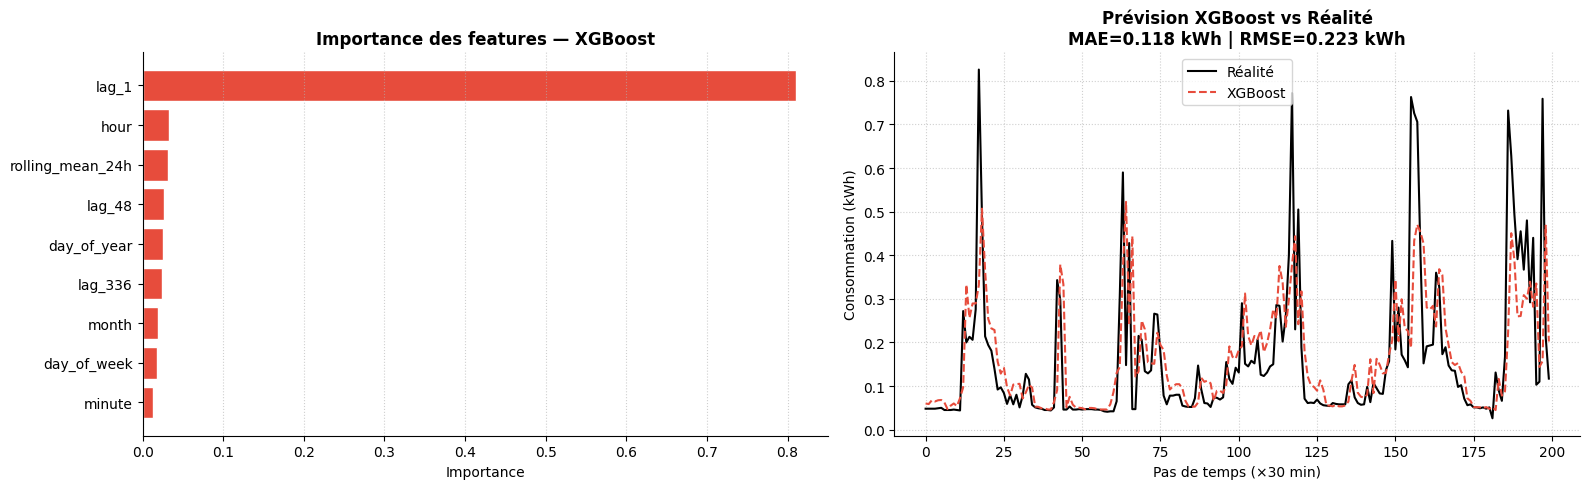

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].barh(importance["Feature"], importance["Importance"], color="#E74C3C", edgecolor="white")
axes[0].invert_yaxis()
axes[0].set_title("Importance des features — XGBoost", fontweight="bold")
axes[0].set_xlabel("Importance")
axes[0].grid(axis="x", linestyle=":", alpha=0.6); axes[0].spines[["top","right"]].set_visible(False)

N = 200
axes[1].plot(range(N), y_test_x.values[:N], color="black",   linewidth=1.5, label="Réalité")
axes[1].plot(range(N), preds_xgb[:N],        color="#E74C3C", linewidth=1.5, linestyle="--", label="XGBoost")
axes[1].set_title(f"Prévision XGBoost vs Réalité\nMAE={mae_xgb:.3f} kWh | RMSE={rmse_xgb:.3f} kWh", fontweight="bold")
axes[1].set_xlabel("Pas de temps (×30 min)"); axes[1].set_ylabel("Consommation (kWh)")
axes[1].legend(); axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].spines[["top","right"]].set_visible(False)
plt.tight_layout(); plt.savefig("fig_xgboost_resultats.png", dpi=150, bbox_inches="tight"); plt.show()

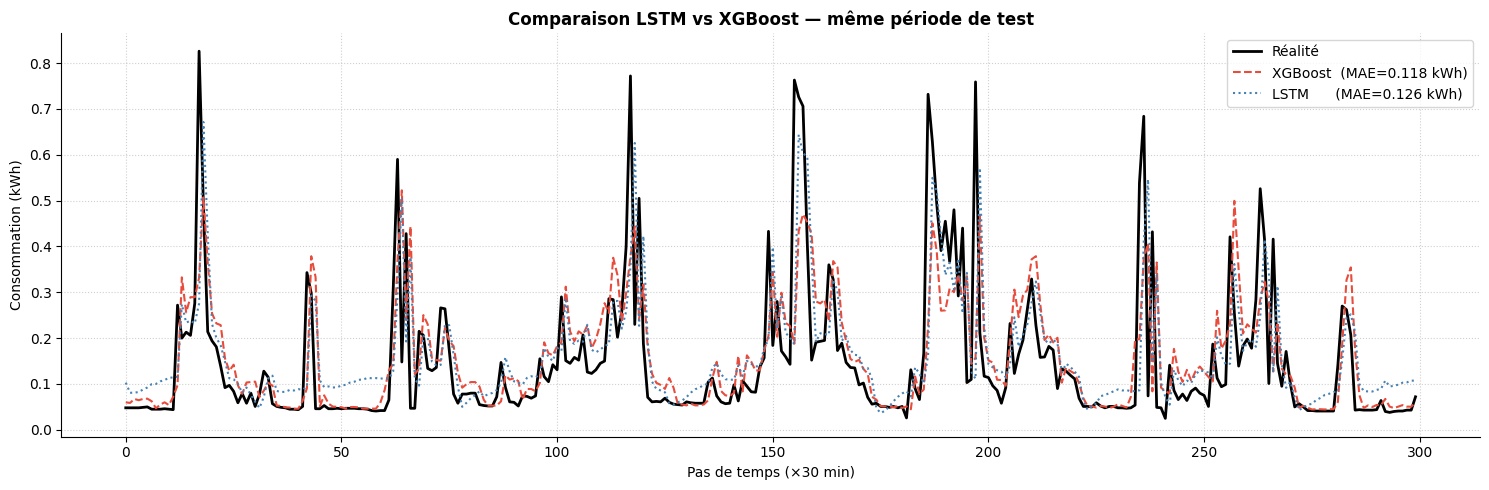

Période commune : 2013-03-14 → 2013-06-30


In [ ]:
# Comparaison LSTM vs XGBoost — même période
ts_xgb_idx  = pd.to_datetime(X_test_x.index.map(lambda i: df_xgb.loc[i, "timestamp"]))
ts_lstm_idx = pd.to_datetime(timestamps_lstm)

common_start = max(ts_xgb_idx[0],  ts_lstm_idx[0])
common_end   = min(ts_xgb_idx[-1], ts_lstm_idx[-1])

mask_x = (ts_xgb_idx  >= common_start) & (ts_xgb_idx  <= common_end)
mask_l = (ts_lstm_idx >= common_start) & (ts_lstm_idx <= common_end)

real_c   = y_test_x.values[mask_x]
pred_x_c = preds_xgb[mask_x]
pred_l_c = preds_lstm_kwh[mask_l]

mae_x_c = mean_absolute_error(real_c, pred_x_c)
mae_l_c = mean_absolute_error(real_c, pred_l_c)

N = 300
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(range(N), real_c[:N],   color="black",    linewidth=2,   label="Réalité")
ax.plot(range(N), pred_x_c[:N], color="#E74C3C",  linewidth=1.5, linestyle="--",
        label=f"XGBoost  (MAE={mae_x_c:.3f} kWh)")
ax.plot(range(N), pred_l_c[:N], color="steelblue", linewidth=1.5, linestyle=":",
        label=f"LSTM      (MAE={mae_l_c:.3f} kWh)")
ax.set_title("Comparaison LSTM vs XGBoost — même période de test", fontweight="bold")
ax.set_xlabel("Pas de temps (×30 min)"); ax.set_ylabel("Consommation (kWh)")
ax.legend(fontsize=10); ax.grid(True, linestyle=":", alpha=0.6)
ax.spines[["top","right"]].set_visible(False)
plt.tight_layout(); plt.savefig("fig_comparaison_lstm_xgboost.png", dpi=150, bbox_inches="tight"); plt.show()
print(f"Période commune : {common_start.date()} → {common_end.date()}")

## 6. Multi-horizon (Direct Multi-Step Forecasting)
6 modèles XGBoost entraînés indépendamment : +30 min → +3 h

In [ ]:
df_mh = df_xgb.copy()
HORIZONS = 6
for h in range(1, HORIZONS+1):
    df_mh[f"target_{h}"] = df_mh["kWh"].shift(-h)

df_mh = df_mh.dropna().reset_index(drop=True)
X_mh = df_mh[features_xgb]

train_end_mh = int(len(X_mh)*0.85)
X_train_mh   = X_mh.iloc[:train_end_mh]
X_test_mh    = X_mh.iloc[train_end_mh:]

modeles_mh = {}; maes_mh = []

for h in range(1, HORIZONS+1):
    y_h       = df_mh[f"target_{h}"]
    y_train_h = y_h.iloc[:train_end_mh]
    y_test_h  = y_h.iloc[train_end_mh:]
    m = xgb.XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=5, random_state=42)
    m.fit(X_train_mh, y_train_h, verbose=False)
    preds_h = m.predict(X_test_mh)
    mae_h   = mean_absolute_error(y_test_h, preds_h)
    maes_mh.append(mae_h)
    modeles_mh[f"horizon_{h}"] = m
    print(f"Modèle +{h*30:3d} min entraîné | MAE : {mae_h:.3f} kWh")

print(f"MAE moyenne 3h : {np.mean(maes_mh):.3f} kWh")

Modèle + 30 min entraîné | MAE : 0.180 kWh
Modèle + 60 min entraîné | MAE : 0.202 kWh
Modèle + 90 min entraîné | MAE : 0.206 kWh
Modèle +120 min entraîné | MAE : 0.205 kWh
Modèle +150 min entraîné | MAE : 0.208 kWh
Modèle +180 min entraîné | MAE : 0.210 kWh
MAE moyenne 3h : 0.202 kWh


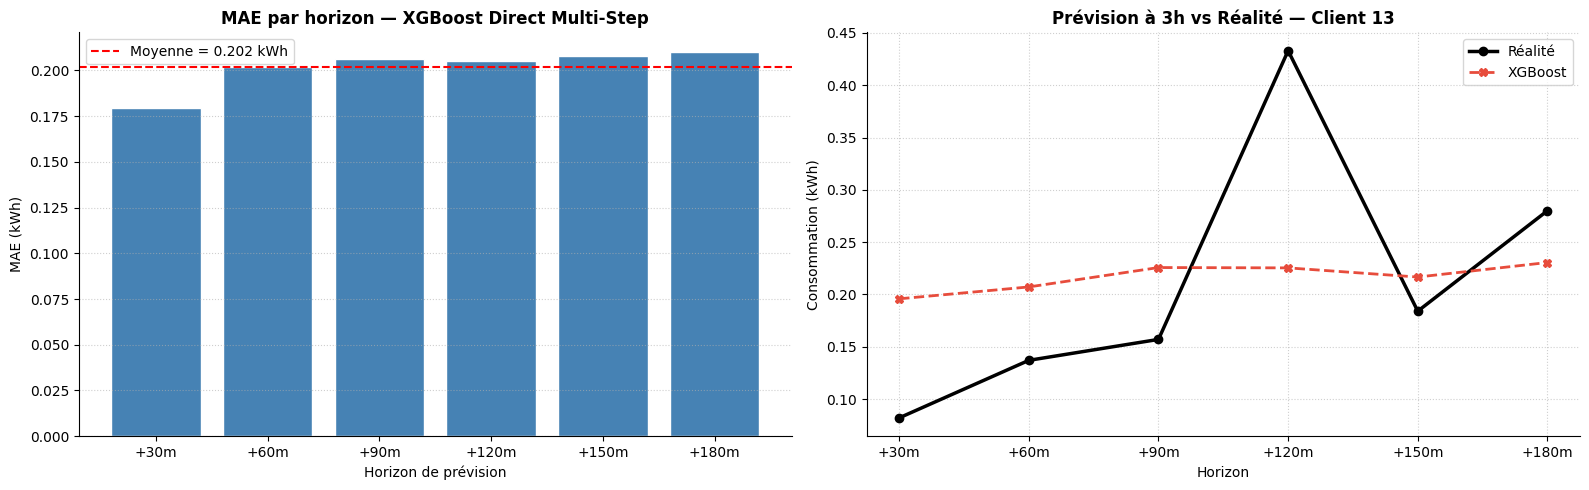

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

horizons_labels = [f"+{h*30}m" for h in range(1, HORIZONS+1)]
axes[0].bar(horizons_labels, maes_mh, color="steelblue", edgecolor="white")
axes[0].axhline(np.mean(maes_mh), color="red", linestyle="--", linewidth=1.5,
                label=f"Moyenne = {np.mean(maes_mh):.3f} kWh")
axes[0].set_title("MAE par horizon — XGBoost Direct Multi-Step", fontweight="bold")
axes[0].set_xlabel("Horizon de prévision"); axes[0].set_ylabel("MAE (kWh)")
axes[0].legend(); axes[0].grid(axis="y", linestyle=":", alpha=0.6)
axes[0].spines[["top","right"]].set_visible(False)

IDX_T = 150
instant_T = X_test_mh.iloc[[IDX_T]]
preds_3h  = [modeles_mh[f"horizon_{h}"].predict(instant_T)[0] for h in range(1, HORIZONS+1)]
reals_3h  = [df_mh[f"target_{h}"].iloc[train_end_mh+IDX_T] for h in range(1, HORIZONS+1)]

axes[1].plot(horizons_labels, reals_3h, marker="o", color="black",  linewidth=2.5, label="Réalité", markersize=6)
axes[1].plot(horizons_labels, preds_3h, marker="X", color="#E74C3C", linewidth=2, linestyle="--", label="XGBoost", markersize=6)
axes[1].set_title(f"Prévision à 3h vs Réalité — Client {CUSTOMER_ID}", fontweight="bold")
axes[1].set_xlabel("Horizon"); axes[1].set_ylabel("Consommation (kWh)")
axes[1].legend(); axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].spines[["top","right"]].set_visible(False)
plt.tight_layout(); plt.savefig("fig_multihorizon.png", dpi=150, bbox_inches="tight"); plt.show()

In [ ]:
N_JOUR = 48

def predict_serie_xgb(n_steps):
    n     = min(n_steps, len(X_test_mh))
    preds = modeles_mh["horizon_1"].predict(X_test_mh.iloc[:n])
    preds = np.maximum(0, preds)
    reals = df_mh["kWh"].iloc[train_end_mh : train_end_mh + n].values
    ts    = df_mh["timestamp"].iloc[train_end_mh : train_end_mh + n].values
    return ts, reals, preds

ts_jour, reals_jour, preds_jour = predict_serie_xgb(N_JOUR)
mae_jour = mean_absolute_error(reals_jour, preds_jour)
print(f"MAE 1 jour : {mae_jour:.3f} kWh  ({len(reals_jour)} pas)")

MAE 1 jour : 0.077 kWh  (48 pas)


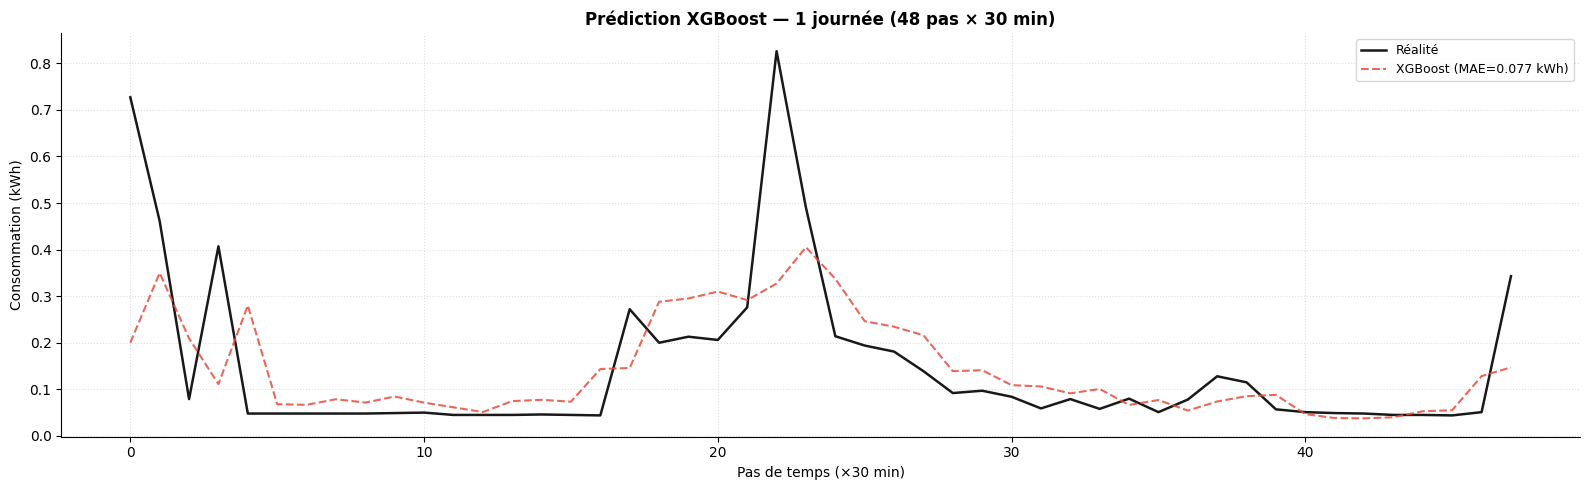

In [ ]:
fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(range(len(reals_jour)), reals_jour, color='black',   linewidth=1.8, label='Réalité', alpha=0.9)
ax.plot(range(len(preds_jour)), preds_jour, color='#E74C3C', linewidth=1.5, linestyle='--',
        label=f'XGBoost (MAE={mae_jour:.3f} kWh)', alpha=0.85)
ax.set_title("Prédiction XGBoost — 1 journée (48 pas × 30 min)", fontweight='bold')
ax.set_xlabel("Pas de temps (×30 min)"); ax.set_ylabel("Consommation (kWh)")
ax.legend(fontsize=9); ax.grid(True, linestyle=':', alpha=0.4)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.show()

## 7. Résolution du problème d'optimisation (LP + EMS Glouton)

In [ ]:
# ── FONCTION EMS LP (PuLP) — CORRIGÉE (boucle dupliquée supprimée) ────────
def ems_lp_pulp(load_arr, pv_arr, timestamps_arr,
                battery_capacity=7.0, soc_min_pct=0.10, soc_max_pct=0.90,
                eta_c=0.90, eta_d=0.90, p_max_kwh=1.5,
                peak_buy=0.40, offpeak_buy=0.20, sell_price=0.08,
                peak_hours=range(17,21), s_init=None):
    T       = len(load_arr)
    SOC_MIN = soc_min_pct * battery_capacity
    SOC_MAX = soc_max_pct * battery_capacity
    if s_init is None:
        s_init = SOC_MIN

    prob  = pulp.LpProblem("EMS_LP", pulp.LpMinimize)
    g_imp = [pulp.LpVariable(f"g_imp_{t}", lowBound=0) for t in range(T)]
    g_exp = [pulp.LpVariable(f"g_exp_{t}", lowBound=0) for t in range(T)]
    c     = [pulp.LpVariable(f"c_{t}", lowBound=0, upBound=p_max_kwh) for t in range(T)]
    d     = [pulp.LpVariable(f"d_{t}", lowBound=0, upBound=p_max_kwh) for t in range(T)]
    s     = [pulp.LpVariable(f"s_{t}", lowBound=SOC_MIN, upBound=SOC_MAX) for t in range(T)]

    hour_arr = pd.to_datetime(timestamps_arr).hour
    prices   = [peak_buy if h in peak_hours else offpeak_buy for h in hour_arr]
    prob    += pulp.lpSum(prices[t]*g_imp[t] - sell_price*g_exp[t] for t in range(T))

    for t in range(T):
        P_t = float(pv_arr[t]); L_t = float(load_arr[t])
        prob += P_t + d[t] + g_imp[t] == L_t + c[t] + g_exp[t]
        if t == 0:
            prob += s[t] == s_init + eta_c*c[t] - d[t]/eta_d
        else:
            prob += s[t] == s[t-1] + eta_c*c[t] - d[t]/eta_d

    prob.solve(pulp.PULP_CBC_CMD(msg=0))
    status = pulp.LpStatus[prob.status]
    if prob.status != 1:
        return {"status": status, "cost": None}

    return {
        "status": status,
        "cost":   pulp.value(prob.objective),
        "g_imp":  np.array([pulp.value(g_imp[t]) for t in range(T)]),
        "g_exp":  np.array([pulp.value(g_exp[t]) for t in range(T)]),
        "c":      np.array([pulp.value(c[t])     for t in range(T)]),
        "d":      np.array([pulp.value(d[t])     for t in range(T)]),
        "soc":    np.array([pulp.value(s[t])     for t in range(T)]),
    }

print("Fonction ems_lp_pulp définie.")

Fonction ems_lp_pulp définie.


In [ ]:
# FONCTION EMS GLOUTON (coûts)
def ems_glouton(load_arr, pv_arr, timestamps_arr,
                battery_capacity=7.0, soc_min_pct=0.10, soc_max_pct=0.90,
                eta_c=0.90, eta_d=0.90, p_max_kwh=1.5,
                peak_buy=0.40, offpeak_buy=0.20, sell_price=0.08,
                peak_hours=range(17,21)):
    """
    EMS Glouton avec coûts cohérents :
      cost = achats_réseau - revenus_injection
    (même convention que ems_lp_pulp et que la référence annuelle)
    """
    T       = len(load_arr)
    SOC_MIN = soc_min_pct * battery_capacity
    SOC_MAX = soc_max_pct * battery_capacity

    soc_list   = [SOC_MIN]
    g_imp_arr  = []; g_exp_arr = []; c_arr = []; d_arr = []
    cost_buy   = 0.0   # achats réseau
    cost_sell  = 0.0   # revenus injection
    hours = pd.to_datetime(timestamps_arr).hour

    for t in range(T):
        curr_soc = soc_list[-1]
        net      = load_arr[t] - pv_arr[t]
        buy_p    = peak_buy if hours[t] in peak_hours else offpeak_buy
        max_ch   = min(p_max_kwh, SOC_MAX - curr_soc)
        max_dis  = min(p_max_kwh, curr_soc - SOC_MIN)

        if net <= 0:
            surplus = -net
            charge  = min(surplus * eta_c, max_ch)
            export  = max(0.0, surplus - charge / eta_c)
            soc_list.append(curr_soc + charge)
            c_arr.append(charge / eta_c); d_arr.append(0.0)
            g_imp_arr.append(0.0); g_exp_arr.append(export)
            cost_sell += sell_price * export   # positif (revenu)
        else:
            need      = net
            discharge = min(need / eta_d, max_dis)
            residual  = max(0.0, need - discharge * eta_d)
            soc_list.append(curr_soc - discharge)
            c_arr.append(0.0); d_arr.append(discharge)
            g_imp_arr.append(residual); g_exp_arr.append(0.0)
            cost_buy += buy_p * residual

    cost_net = cost_buy - cost_sell   # coût NET cohérent

    return {
        "status": "Optimal",
        "cost":   cost_net,            # coût net (peut être légèrement < 0 si très gros export)
        "cost_buy":  cost_buy,
        "cost_sell": cost_sell,
        "g_imp": np.array(g_imp_arr), "g_exp": np.array(g_exp_arr),
        "c":     np.array(c_arr),     "d":     np.array(d_arr),
        "soc":   np.array(soc_list[1:]),
    }

print("Fonction ems_glouton définie.")

Fonction ems_glouton définie.


In [ ]:
def get_pv_for_timestamps(timestamps_list):
    ts_series  = pd.to_datetime(timestamps_list)
    pv_aligned = df_final['PV'].reindex(ts_series, method='nearest', tolerance=pd.Timedelta('1min'))
    n_missing  = pv_aligned.isna().sum()
    if n_missing > 0:
        print(f"  [AVERT] {n_missing} timestamps PV non trouvés → fillna(0)")
        pv_aligned = pv_aligned.fillna(0.0)
    return pv_aligned.values

pv_jour = get_pv_for_timestamps(ts_jour)

print("Résolution LP — 1 jour...")
res_lp_jour = ems_lp_pulp(preds_jour, pv_jour, ts_jour)
res_gl_jour = ems_glouton(preds_jour, pv_jour, ts_jour)
res_gl_reel = ems_glouton(load_reel, pv_reel, ts_reel)
print(f"  LP      : coût = {res_lp_jour['cost']:.4f} €  | {res_lp_jour['status']}")
print(f"  Glouton : coût = {res_gl_jour['cost']:.4f} €")
if res_lp_jour['cost'] and res_gl_jour['cost']:
    gap = (res_gl_jour['cost'] - res_lp_jour['cost']) / max(abs(res_gl_jour['cost']), 1e-6) * 100
    print(f"  Gap LP/Glouton : {gap:.1f} %")

Résolution LP — 1 jour...
  LP      : coût = 0.2926 €  | Optimal
  Glouton : coût = 0.2926 €
  Gap LP/Glouton : 0.0 %


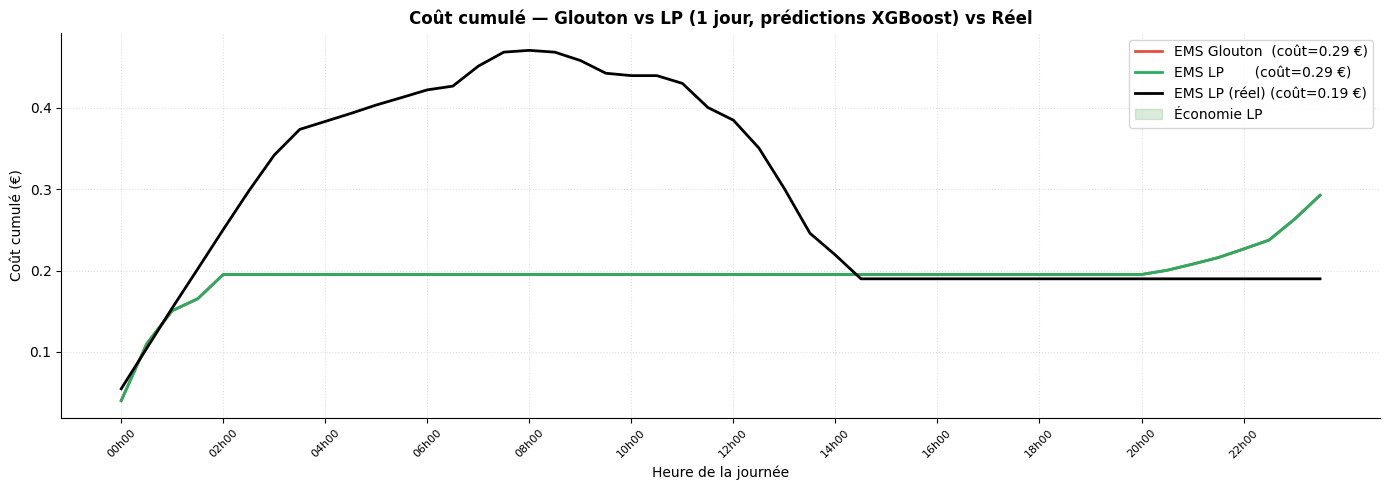

In [89]:
hours_lp  = pd.to_datetime(ts_jour).hour
hours_gl  = pd.to_datetime(ts_jour).hour
hours_reel = pd.to_datetime(ts_reel).hour

prices_lp = np.array([PEAK_BUY_PRICE if h in PEAK_HOURS
                       else OFFPEAK_BUY_PRICE for h in hours_lp])
prices_gl = prices_lp.copy()
prices_reel = np.array([PEAK_BUY_PRICE if h in PEAK_HOURS
                         else OFFPEAK_BUY_PRICE for h in hours_reel])

cout_cum_lp = (res_lp_jour['g_imp'] * prices_lp -
               res_lp_jour['g_exp'] * SELL_PRICE).cumsum()
cout_cum_gl = (res_gl_jour['g_imp'] * prices_gl -
               res_gl_jour['g_exp'] * SELL_PRICE).cumsum()
cout_cum_reel = (res_lp_reel['g_imp'] * prices_reel -
                 res_lp_reel['g_exp'] * SELL_PRICE).cumsum()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(range(len(cout_cum_gl)), cout_cum_gl, color='#E74C3C', linewidth=2,
        label=f"EMS Glouton  (coût={res_gl_jour['cost']:.2f} €)")
ax.plot(range(len(cout_cum_lp)), cout_cum_lp, color='#27ae60', linewidth=2,
        label=f"EMS LP       (coût={res_lp_jour['cost']:.2f} €)")
ax.plot(range(len(cout_cum_reel)), cout_cum_reel, color='black', linewidth=2,
        label=f"EMS LP (réel) (coût={res_lp_reel['cost']:.2f} €)")

t_ax = [f"{i//2:02d}h{(i%2)*30:02d}" for i in range(len(cout_cum_lp))]
ax.fill_between(range(len(cout_cum_lp)), cout_cum_gl, cout_cum_lp,
                alpha=0.15, color='green', label='Économie LP')
ax.set_title("Coût cumulé — Glouton vs LP (1 jour, prédictions XGBoost) vs Réel",
             fontweight='bold')
ax.set_ylabel("Coût cumulé (€)")
ax.set_xlabel("Heure de la journée")
ax.set_xticks(range(0, len(t_ax), 4))
ax.set_xticklabels(t_ax[::4], rotation=45, fontsize=8)
ax.legend(fontsize=10)
ax.grid(True, linestyle=':', alpha=0.4)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

In [90]:
# ============================================================
# OPTIMISATION LINÉAIRE AVEC LES VRAIES DONNÉES DU DATASET


# 1) On prépare les vraies données
df_real = df_final.copy()

# Si timestamp est une colonne, on le met en index
if "timestamp" in df_real.columns:
    df_real["timestamp"] = pd.to_datetime(df_real["timestamp"])
    df_real = df_real.set_index("timestamp")

# On s'assure que l'index est bien temporel
df_real.index = pd.to_datetime(df_real.index)
df_real = df_real.sort_index()

# 2) On reconstruit Load si nécessaire
# Load = consommation totale réelle = GC + CL
if "Load" not in df_real.columns:
    df_real["Load"] = df_real["GC"] + df_real["CL"]

# 3) On reconstruit PV si nécessaire
# PV = production photovoltaïque réelle = GG
if "PV" not in df_real.columns:
    df_real["PV"] = df_real["GG"]

# 4) Choix d'une journée réelle du dataset
# Tu peux changer la date si tu veux tester une autre journée
JOUR_REEL = "2013-01-15"

df_jour_reel = df_real.loc[JOUR_REEL].copy()

# Sécurité : on garde uniquement les lignes où Load et PV existent
df_jour_reel = df_jour_reel[["Load", "PV"]].dropna()

# 5) Extraction des vraies données pour l'optimisation
load_reel = df_jour_reel["Load"].values
pv_reel   = df_jour_reel["PV"].values
ts_reel   = df_jour_reel.index.values

print(f"Nombre de pas de temps utilisés : {len(load_reel)}")
print(f"Date étudiée : {JOUR_REEL}")

# 6) Résolution du problème d'optimisation linéaire avec les vraies données
res_lp_reel = ems_lp_pulp(load_reel, pv_reel, ts_reel)

# 7) Affichage des résultats
print("Résolution LP avec vraies données")
print(f"Statut du solveur : {res_lp_reel['status']}")
print(f"Coût optimal sur la journée : {res_lp_reel['cost']:.4f} €")

print(f"Import réseau total : {res_lp_reel['g_imp'].sum():.3f} kWh")
print(f"Export réseau total : {res_lp_reel['g_exp'].sum():.3f} kWh")
print(f"Charge batterie totale : {res_lp_reel['c'].sum():.3f} kWh")
print(f"Décharge batterie totale : {res_lp_reel['d'].sum():.3f} kWh")

Nombre de pas de temps utilisés : 48
Date étudiée : 2013-01-15
Résolution LP avec vraies données
Statut du solveur : Optimal
Coût optimal sur la journée : 0.1898 €
Import réseau total : 2.354 kWh
Export réseau total : 3.512 kWh
Charge batterie totale : 3.094 kWh
Décharge batterie totale : 2.506 kWh


Période étudiée : 2012-07-01 → 2013-06-30
Nombre de pas de temps : 17520
Nombre de jours équivalent : 365.0

Résolution LP réel sur un an...
Résolution EMS glouton réel sur un an...

Résultats annuels
LP réel      : coût = 480.85 € | statut = Optimal
Glouton réel : coût = 546.63 €
Gap LP / Glouton : 12.03 %


,LP réel,Glouton réel
Import réseau total (kWh),2162.53,2109.13
Export réseau total (kWh),447.62,447.62
Charge batterie totale (kWh),1779.77,1498.74
Décharge batterie totale (kWh),1441.61,1348.87
Coût net total (€),480.85,546.63


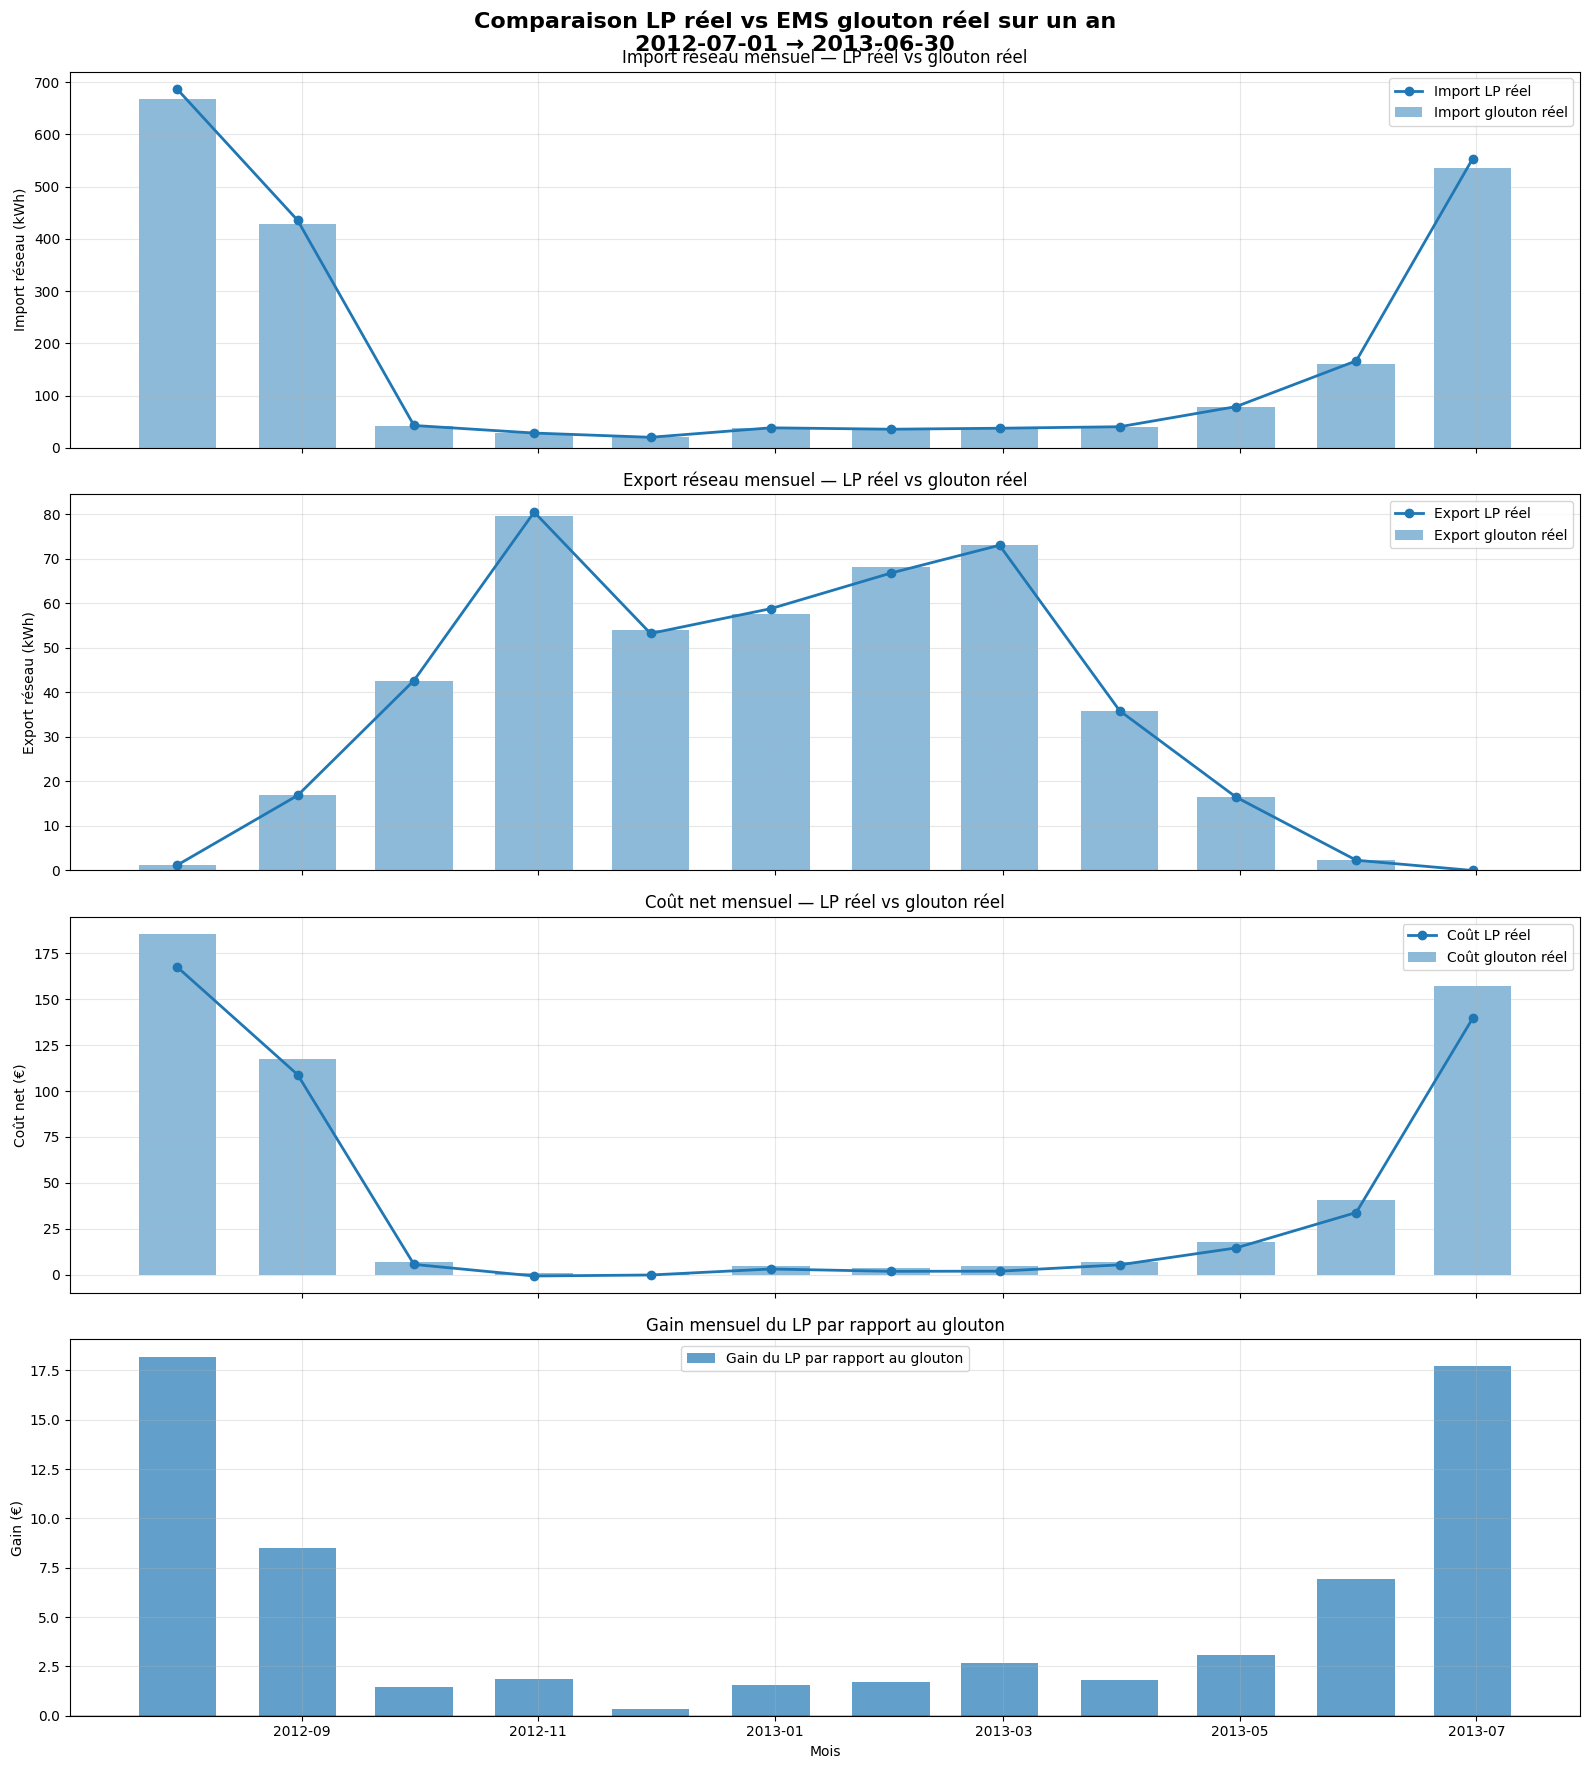


Moyenne mensuelle → LP : 40.07 €/mois  |  Glouton : 45.55 €/mois  |  Gain LP/Glouton : 5.48 €/mois


In [91]:
# ============================================================
# LP RÉEL vs GLOUTON — COMPARAISON SUR UN AN
# ============================================================

# ------------------------------------------------------------
# 1) Préparation des vraies données
# ------------------------------------------------------------

df_real = df_final.copy()

# Si timestamp est une colonne, on le met en index
if "timestamp" in df_real.columns:
    df_real["timestamp"] = pd.to_datetime(df_real["timestamp"])
    df_real = df_real.set_index("timestamp")

# Sécurité : index temporel trié
df_real.index = pd.to_datetime(df_real.index)
df_real = df_real.sort_index()

# Reconstruction de Load si nécessaire
# Load = consommation réelle totale = GC + CL
if "Load" not in df_real.columns:
    df_real["Load"] = df_real["GC"] + df_real["CL"]

# Reconstruction de PV si nécessaire
# PV = production photovoltaïque réelle = GG
if "PV" not in df_real.columns:
    df_real["PV"] = df_real["GG"]

# ------------------------------------------------------------
# 2) Choix de l'année étudiée
# ------------------------------------------------------------

DATE_DEBUT = "2012-07-01"
NB_JOURS = 365

date_debut = pd.to_datetime(DATE_DEBUT)
date_fin = date_debut + pd.Timedelta(days=NB_JOURS)

df_an = df_real.loc[
    (df_real.index >= date_debut) & (df_real.index < date_fin),
    ["Load", "PV"]
].dropna()

load_an = df_an["Load"].values
pv_an   = df_an["PV"].values
ts_an   = df_an.index.values

print("Période étudiée :", date_debut.date(), "→", (date_fin - pd.Timedelta(days=1)).date())
print("Nombre de pas de temps :", len(df_an))
print("Nombre de jours équivalent :", len(df_an) / 48)

# ------------------------------------------------------------
# 3) Résolution LP réel et glouton réel sur un an
# ------------------------------------------------------------

print("\nRésolution LP réel sur un an...")
res_lp_an = ems_lp_pulp(load_an, pv_an, ts_an)

print("Résolution EMS glouton réel sur un an...")
res_gl_an = ems_glouton(load_an, pv_an, ts_an)

print("\nRésultats annuels")
print(f"LP réel      : coût = {res_lp_an['cost']:.2f} € | statut = {res_lp_an['status']}")
print(f"Glouton réel : coût = {res_gl_an['cost']:.2f} €")

if res_lp_an["cost"] is not None and res_gl_an["cost"] is not None:
    gap = (res_gl_an["cost"] - res_lp_an["cost"]) / max(abs(res_gl_an["cost"]), 1e-6) * 100
    print(f"Gap LP / Glouton : {gap:.2f} %")

# ------------------------------------------------------------
# 4) Construction d'un DataFrame de comparaison
# ------------------------------------------------------------

df_comp_an = pd.DataFrame(index=df_an.index)

df_comp_an["Load"] = load_an
df_comp_an["PV"] = pv_an

# Résultats LP
df_comp_an["LP_import"] = res_lp_an["g_imp"]
df_comp_an["LP_export"] = res_lp_an["g_exp"]
df_comp_an["LP_charge"] = res_lp_an["c"]
df_comp_an["LP_decharge"] = res_lp_an["d"]
df_comp_an["LP_soc"] = res_lp_an["soc"]

# Résultats glouton
df_comp_an["GL_import"] = res_gl_an["g_imp"]
df_comp_an["GL_export"] = res_gl_an["g_exp"]
df_comp_an["GL_charge"] = res_gl_an["c"]
df_comp_an["GL_decharge"] = res_gl_an["d"]
df_comp_an["GL_soc"] = res_gl_an["soc"]

# Prix horaires
hours_an = df_comp_an.index.hour

PEAK_BUY_PRICE = 0.40
OFFPEAK_BUY_PRICE = 0.20
SELL_PRICE = 0.08
PEAK_HOURS = range(17, 21)

df_comp_an["buy_price"] = [
    PEAK_BUY_PRICE if h in PEAK_HOURS else OFFPEAK_BUY_PRICE
    for h in hours_an
]

# Coûts instantanés
df_comp_an["LP_cost"] = (
    df_comp_an["buy_price"] * df_comp_an["LP_import"]
    - SELL_PRICE * df_comp_an["LP_export"]
)

df_comp_an["GL_cost"] = (
    df_comp_an["buy_price"] * df_comp_an["GL_import"]
    - SELL_PRICE * df_comp_an["GL_export"]
)

# ------------------------------------------------------------
# 5) Bilan annuel chiffré
# ------------------------------------------------------------

bilan_annuel = pd.DataFrame({
    "LP réel": [
        df_comp_an["LP_import"].sum(),
        df_comp_an["LP_export"].sum(),
        df_comp_an["LP_charge"].sum(),
        df_comp_an["LP_decharge"].sum(),
        df_comp_an["LP_cost"].sum()
    ],
    "Glouton réel": [
        df_comp_an["GL_import"].sum(),
        df_comp_an["GL_export"].sum(),
        df_comp_an["GL_charge"].sum(),
        df_comp_an["GL_decharge"].sum(),
        df_comp_an["GL_cost"].sum()
    ]
}, index=[
    "Import réseau total (kWh)",
    "Export réseau total (kWh)",
    "Charge batterie totale (kWh)",
    "Décharge batterie totale (kWh)",
    "Coût net total (€)"
])

display(bilan_annuel.round(2))

# ------------------------------------------------------------
# 6) Agrégation mensuelle pour affichage lisible
# ------------------------------------------------------------

df_mois = df_comp_an.resample("M").sum(numeric_only=True)

# ------------------------------------------------------------
# 7) Graphiques LP réel vs glouton réel sur un an
# ------------------------------------------------------------

fig, axes = plt.subplots(4, 1, figsize=(16, 18), sharex=True)

# Graphique 1 : imports mensuels
axes[0].bar(
    df_mois.index,
    df_mois["GL_import"],
    width=20,
    alpha=0.5,
    label="Import glouton réel"
)

axes[0].plot(
    df_mois.index,
    df_mois["LP_import"],
    marker="o",
    linewidth=2,
    label="Import LP réel"
)

axes[0].set_title("Import réseau mensuel — LP réel vs glouton réel")
axes[0].set_ylabel("Import réseau (kWh)")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Graphique 2 : exports mensuels
axes[1].bar(
    df_mois.index,
    df_mois["GL_export"],
    width=20,
    alpha=0.5,
    label="Export glouton réel"
)

axes[1].plot(
    df_mois.index,
    df_mois["LP_export"],
    marker="o",
    linewidth=2,
    label="Export LP réel"
)

axes[1].set_title("Export réseau mensuel — LP réel vs glouton réel")
axes[1].set_ylabel("Export réseau (kWh)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

# Graphique 3 : coût mensuel
axes[2].bar(
    df_mois.index,
    df_mois["GL_cost"],
    width=20,
    alpha=0.5,
    label="Coût glouton réel"
)

axes[2].plot(
    df_mois.index,
    df_mois["LP_cost"],
    marker="o",
    linewidth=2,
    label="Coût LP réel"
)

axes[2].set_title("Coût net mensuel — LP réel vs glouton réel")
axes[2].set_ylabel("Coût net (€)")
axes[2].grid(True, alpha=0.3)
axes[2].legend()

# Graphique 4 : différence de coût mensuelle
df_mois["gain_LP_vs_GL"] = df_mois["GL_cost"] - df_mois["LP_cost"]

axes[3].bar(
    df_mois.index,
    df_mois["gain_LP_vs_GL"],
    width=20,
    alpha=0.7,
    label="Gain du LP par rapport au glouton"
)

axes[3].axhline(0, color="black", linewidth=1)
axes[3].set_title("Gain mensuel du LP par rapport au glouton")
axes[3].set_ylabel("Gain (€)")
axes[3].set_xlabel("Mois")
axes[3].grid(True, alpha=0.3)
axes[3].legend()

fig.suptitle(
    f"Comparaison LP réel vs EMS glouton réel sur un an\n{date_debut.date()} → {(date_fin - pd.Timedelta(days=1)).date()}",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig("fig_lp_reel_vs_glouton_1_an.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"\nMoyenne mensuelle → LP : {bilan_annuel.loc['Coût net total (€)','LP réel']/12:.2f} €/mois  |  Glouton : {bilan_annuel.loc['Coût net total (€)','Glouton réel']/12:.2f} €/mois  |  Gain LP/Glouton : {(bilan_annuel.loc['Coût net total (€)','Glouton réel']-bilan_annuel.loc['Coût net total (€)','LP réel'])/12:.2f} €/mois")

## 8. Bilan

In [ ]:
print("=" * 72)
print(f"{'BILAN FINAL — CLIENT 13':^72}")
print("=" * 72)
print(f"{'Scénario':<32} {'Import (kWh)':>12} {'Export (kWh)':>12} {'Coût (€)':>10}")
print("-" * 72)

ref_import = df_final['Grid_Import'].sum()
ref_cost   = (df_final.loc[df_final.index.hour.isin(range(17,21)), 'Grid_Import'].sum() * 0.40 +
              df_final.loc[~df_final.index.hour.isin(range(17,21)),'Grid_Import'].sum() * 0.20)
print(f"{'Sans batterie (réel)':<32} {ref_import:>12.0f} {'0':>12} {ref_cost:>10.1f}")
print("-" * 72)

rows = [
    ("EMS Glouton — 1 jour", res_gl_jour),
    ("EMS LP     — 1 jour",  res_lp_jour),
]
for label, res in rows:
    if res['cost'] is not None:
        imp = res['g_imp'].sum(); exp = res['g_exp'].sum()
        print(f"{label:<32} {imp:>12.1f} {exp:>12.1f} {res['cost']:>10.2f}")

print("=" * 72)

                        BILAN FINAL — CLIENT 13                         
Scénario                         Import (kWh) Export (kWh)   Coût (€)
------------------------------------------------------------------------
Sans batterie (réel)                     3323            0      948.3
------------------------------------------------------------------------
EMS Glouton — 1 jour                      1.5          0.0       0.29
EMS LP     — 1 jour                       1.5          0.0       0.29


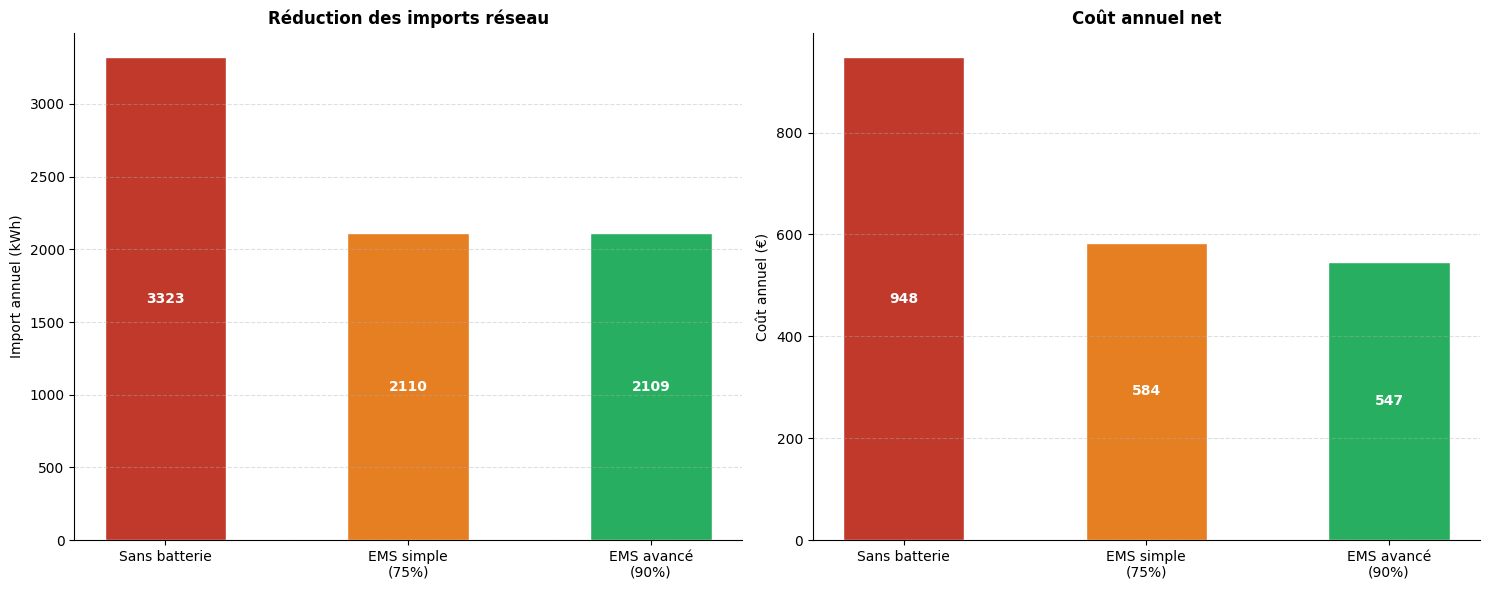

In [ ]:
labels_b  = ["Sans batterie", "EMS simple\n(75%)", "EMS avancé\n(90%)"]
imps_b    = [df_final['Grid_Import'].sum(),
             df_final['Grid_Import_Batt'].sum(),
             df_final['Grid_Import_smart_ems'].sum()]
costs_b   = [ref_cost,
             (df_final.loc[ peak_mask,"Grid_Import_Batt"].sum()*PEAK_BUY_PRICE +
              df_final.loc[~peak_mask,"Grid_Import_Batt"].sum()*OFFPEAK_BUY_PRICE),
             cost_adv]
colors_b3 = ["#c0392b", "#e67e22", "#27ae60"]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, values, ylabel, title in zip(
    axes,
    [imps_b, costs_b],
    ["Import annuel (kWh)", "Coût annuel (€)"],
    ["Réduction des imports réseau", "Coût annuel net"]
):
    bars = ax.bar(labels_b, values, color=colors_b3, width=0.5, edgecolor="white")
    for bar, val in zip(bars, values):
        ax.text(bar.get_x()+bar.get_width()/2, val*0.5,
                f"{val:.0f}", ha="center", va="center",
                fontweight="bold", color="white", fontsize=10)
    ax.set_title(title, fontweight="bold")
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.spines[["top","right"]].set_visible(False)

plt.tight_layout()
plt.savefig("fig_bilan_final.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Comparaison des horizons de prédiction

In [ ]:
# Prédiction autorégressive LSTM
def lstm_predict_autoregressive(model, scaler, df_source,
                                 ts_start_idx, sequence_length,
                                 features_list, n_steps, n_recal):
    data_raw = df_source[features_list].values
    data_sc  = scaler.transform(data_raw)
    preds_kwh = []; reals_kwh = []
    window = data_sc[ts_start_idx - sequence_length : ts_start_idx].copy()
    step_in_block = 0

    for step in range(n_steps):
        global_idx = ts_start_idx + step
        if global_idx >= len(data_raw):
            break
        if step_in_block == n_recal:
            window = data_sc[global_idx - sequence_length : global_idx].copy()
            step_in_block = 0

        X_input = window[-sequence_length:].reshape(1, sequence_length, len(features_list))
        pred_sc = model.predict(X_input, verbose=0)[0, 0]

        dummy = np.zeros((1, len(features_list))); dummy[0, 0] = pred_sc
        pred_kwh = max(0.0, scaler.inverse_transform(dummy)[0, 0])
        preds_kwh.append(pred_kwh)
        reals_kwh.append(data_raw[global_idx, 0])

        next_feat = np.array([[pred_sc, data_sc[global_idx, 1], data_sc[global_idx, 2]]])
        window = np.vstack([window[1:], next_feat])
        step_in_block += 1

    return np.array(preds_kwh), np.array(reals_kwh)

n_test_lstm = len(reals_lstm_kwh)

print("LSTM — Jour par Jour...")
preds_lstm_jour, reals_lstm_jour = lstm_predict_autoregressive(
    lstm_model, scaler_lstm, df_lstm,
    ts_lstm_start, SEQUENCE_LENGTH, features_lstm, n_test_lstm, 48)
print(f"  {len(preds_lstm_jour)} pas générés")

print("LSTM — Semaine par Semaine...")
preds_lstm_semaine, reals_lstm_semaine = lstm_predict_autoregressive(
    lstm_model, scaler_lstm, df_lstm,
    ts_lstm_start, SEQUENCE_LENGTH, features_lstm, n_test_lstm, 336)
print(f"  {len(preds_lstm_semaine)} pas générés | LSTM : done.")

LSTM — Jour par Jour...
  5256 pas générés
LSTM — Semaine par Semaine...
  5256 pas générés | LSTM : done.


In [ ]:
# Prédiction autorégressive XGBoost
def xgb_predict_autoregressive(model, df_source, ts_start_idx,
                                features_list, n_steps, n_recal):
    history_len = 336 + 48 + 1
    history_kwh = df_source['kWh'].iloc[ts_start_idx - history_len : ts_start_idx].tolist()
    preds_kwh = []; reals_kwh = []
    step_in_block = 0

    for step in range(n_steps):
        global_idx = ts_start_idx + step
        if global_idx >= len(df_source):
            break
        if step_in_block == n_recal:
            history_kwh   = df_source['kWh'].iloc[global_idx - history_len : global_idx].tolist()
            step_in_block = 0

        row    = df_source.iloc[global_idx]
        lag_1  = history_kwh[-1]   if len(history_kwh) >= 1   else 0.0
        lag_48 = history_kwh[-48]  if len(history_kwh) >= 48  else 0.0
        lag_336= history_kwh[-336] if len(history_kwh) >= 336 else 0.0
        rm24h  = np.mean(history_kwh[-48:]) if len(history_kwh) >= 48 else np.mean(history_kwh)

        fvec = pd.DataFrame([{
            'hour': row['hour'], 'minute': row['minute'],
            'day_of_week': row['day_of_week'], 'month': row['month'],
            'day_of_year': row['day_of_year'],
            'lag_1': lag_1, 'lag_48': lag_48, 'lag_336': lag_336,
            'rolling_mean_24h': rm24h,
        }])[features_list]

        pred_kwh = max(0.0, float(model.predict(fvec)[0]))
        preds_kwh.append(pred_kwh); reals_kwh.append(float(row['kWh']))
        history_kwh.append(pred_kwh); step_in_block += 1

    return np.array(preds_kwh), np.array(reals_kwh)

n_test_xgb = len(preds_xgb)

print("XGBoost — Jour par Jour...")
preds_xgb_jour, reals_xgb_jour = xgb_predict_autoregressive(
    xgb_model, df_xgb, ts_start_xgb, features_xgb, n_test_xgb, 48)
print(f"  {len(preds_xgb_jour)} pas générés")

print("XGBoost — Semaine par Semaine...")
preds_xgb_semaine, reals_xgb_semaine = xgb_predict_autoregressive(
    xgb_model, df_xgb, ts_start_xgb, features_xgb, n_test_xgb, 336)
print(f"  {len(preds_xgb_semaine)} pas générés | XGBoost : done.")

XGBoost — Jour par Jour...
  5213 pas générés
XGBoost — Semaine par Semaine...
  5213 pas générés | XGBoost : done.


In [ ]:
def metrics(reals, preds):
    mae  = mean_absolute_error(reals, preds)
    rmse = np.sqrt(mean_squared_error(reals, preds))
    return mae, rmse

n_l = min(len(preds_lstm_kwh), len(preds_lstm_jour), len(preds_lstm_semaine))
n_x = min(len(preds_xgb),      len(preds_xgb_jour),  len(preds_xgb_semaine))

results_horizons = {
    'LSTM — Pas à Pas'        : metrics(reals_lstm_kwh[:n_l],    preds_lstm_kwh[:n_l]),
    'LSTM — Jour par Jour'    : metrics(reals_lstm_jour[:n_l],   preds_lstm_jour[:n_l]),
    'LSTM — Semaine'          : metrics(reals_lstm_semaine[:n_l], preds_lstm_semaine[:n_l]),
    'XGBoost — Pas à Pas'     : metrics(y_test_x.values[:n_x],   preds_xgb[:n_x]),
    'XGBoost — Jour par Jour' : metrics(reals_xgb_jour[:n_x],    preds_xgb_jour[:n_x]),
    'XGBoost — Semaine'       : metrics(reals_xgb_semaine[:n_x],  preds_xgb_semaine[:n_x]),
}

print(f"{'Combinaison':<30} {'MAE (kWh)':>12} {'RMSE (kWh)':>12}")
print("-" * 56)
for name, (mae, rmse) in results_horizons.items():
    print(f"{name:<30} {mae:>12.3f} {rmse:>12.3f}")

Combinaison                       MAE (kWh)   RMSE (kWh)
--------------------------------------------------------
LSTM — Pas à Pas                      0.125        0.233
LSTM — Jour par Jour                  0.201        0.363
LSTM — Semaine                        0.208        0.380
XGBoost — Pas à Pas                   0.118        0.223
XGBoost — Jour par Jour               0.210        0.328
XGBoost — Semaine                     0.315        0.423


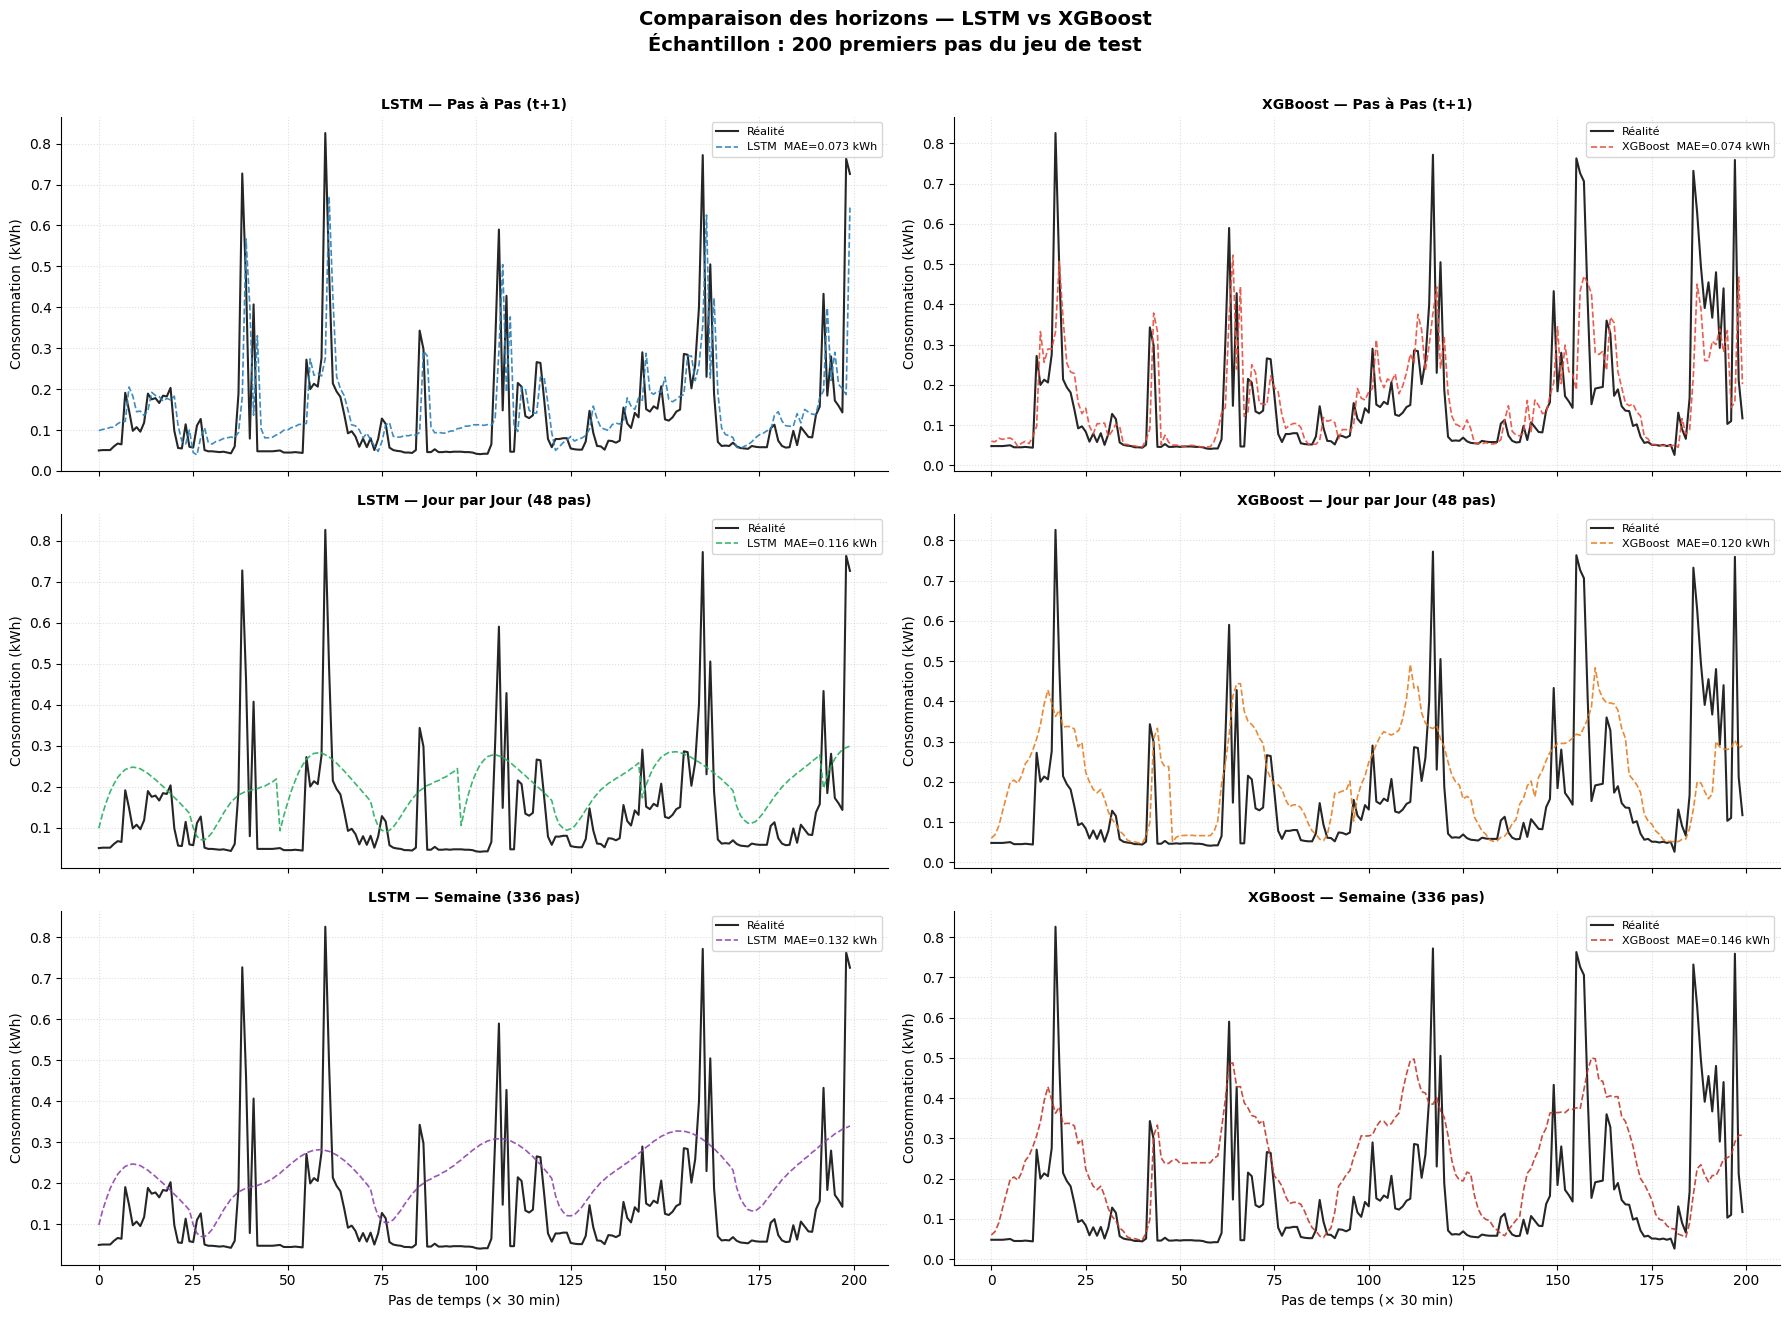

In [ ]:
N_SHOW = 200
real_lstm_ref = reals_lstm_kwh[:N_SHOW]
real_xgb_ref  = y_test_x.values[:N_SHOW]

horizons_plot = [
    ("Pas à Pas (t+1)",       preds_lstm_kwh[:N_SHOW],     preds_xgb[:N_SHOW]),
    ("Jour par Jour (48 pas)", preds_lstm_jour[:N_SHOW],    preds_xgb_jour[:N_SHOW]),
    ("Semaine (336 pas)",      preds_lstm_semaine[:N_SHOW], preds_xgb_semaine[:N_SHOW]),
]
col_l = ["#2980b9", "#27ae60", "#8e44ad"]
col_x = ["#e74c3c", "#e67e22", "#c0392b"]

fig, axes = plt.subplots(3, 2, figsize=(18, 13), sharex=True)
fig.suptitle("Comparaison des horizons — LSTM vs XGBoost\nÉchantillon : 200 premiers pas du jeu de test",
             fontsize=14, fontweight='bold', y=1.01)

for row_idx, (label, pred_l, pred_x) in enumerate(horizons_plot):
    mae_l, _ = metrics(real_lstm_ref[:len(pred_l)], pred_l)
    mae_x, _ = metrics(real_xgb_ref[:len(pred_x)],  pred_x)
    for col_idx, (real, pred, color, mname, mae) in enumerate([
        (real_lstm_ref, pred_l, col_l[row_idx], "LSTM",    mae_l),
        (real_xgb_ref,  pred_x, col_x[row_idx], "XGBoost", mae_x),
    ]):
        ax = axes[row_idx, col_idx]
        ax.plot(range(len(real)), real, color='black', linewidth=1.5, alpha=0.85, label='Réalité')
        ax.plot(range(len(pred)), pred, color=color,   linewidth=1.2, linestyle='--', alpha=0.9,
                label=f'{mname}  MAE={mae:.3f} kWh')
        ax.set_title(f"{mname} — {label}", fontweight='bold', fontsize=10)
        ax.set_ylabel("Consommation (kWh)"); ax.legend(fontsize=8, loc='upper right')
        ax.grid(True, linestyle=':', alpha=0.4); ax.spines[['top','right']].set_visible(False)
        if row_idx == 2:
            ax.set_xlabel("Pas de temps (× 30 min)")

plt.tight_layout(); plt.savefig("fig_comparaison_horizons.png", dpi=150, bbox_inches='tight'); plt.show()

In [ ]:
def get_pv_aligned(df_src, ts_start, n_steps):
    end_idx    = min(ts_start + n_steps, len(df_src))
    ts_arr     = df_src['timestamp'].iloc[ts_start:end_idx].values
    ts_idx     = pd.to_datetime(ts_arr)
    pv_aligned = df_final['PV'].reindex(ts_idx, method='nearest', tolerance=pd.Timedelta('1min'))
    n_missing  = pv_aligned.isna().sum()
    if n_missing > 0:
        print(f"  [AVERT] {n_missing}/{len(ts_idx)} timestamps PV manquants.")
        pv_aligned = pv_aligned.fillna(0.0)
    return pv_aligned.values, ts_arr

pv_lstm_arr, ts_pv_lstm = get_pv_aligned(df_lstm, ts_lstm_start, n_l)
pv_xgb_arr,  ts_pv_xgb  = get_pv_aligned(df_xgb,  ts_start_xgb,  n_x)

ems_configs = {
    'LSTM — Pas à Pas'        : (preds_lstm_kwh[:n_l],    pv_lstm_arr[:n_l], ts_pv_lstm[:n_l]),
    'LSTM — Jour par Jour'    : (preds_lstm_jour[:n_l],   pv_lstm_arr[:n_l], ts_pv_lstm[:n_l]),
    'LSTM — Semaine'          : (preds_lstm_semaine[:n_l], pv_lstm_arr[:n_l], ts_pv_lstm[:n_l]),
    'XGBoost — Pas à Pas'     : (preds_xgb[:n_x],          pv_xgb_arr[:n_x],  ts_pv_xgb[:n_x]),
    'XGBoost — Jour par Jour' : (preds_xgb_jour[:n_x],     pv_xgb_arr[:n_x],  ts_pv_xgb[:n_x]),
    'XGBoost — Semaine'       : (preds_xgb_semaine[:n_x],   pv_xgb_arr[:n_x],  ts_pv_xgb[:n_x]),
}

ems_results_horizons = {}
for name, (load_p, pv_a, ts_a) in ems_configs.items():
    n   = min(len(load_p), len(pv_a))
    res = ems_glouton(load_p[:n], pv_a[:n], ts_a[:n])
    ems_results_horizons[name] = res
    print(f"  {name:<30} coût = {res['cost']:8.2f} €  | import = {res['g_imp'].sum():.1f} kWh")

  LSTM — Pas à Pas               coût =   194.50 €  | import = 729.2 kWh
  LSTM — Jour par Jour           coût =   127.16 €  | import = 527.2 kWh
  LSTM — Semaine                 coût =   123.75 €  | import = 520.8 kWh
  XGBoost — Pas à Pas            coût =   216.04 €  | import = 789.8 kWh
  XGBoost — Jour par Jour        coût =   264.27 €  | import = 1003.9 kWh
  XGBoost — Semaine              coût =   423.56 €  | import = 1710.4 kWh


## 10. Gains financiers annualisés

In [ ]:
# référence cohérente — inclut les revenus d'export comme l'EMS
def ref_cost_periode(timestamps_arr):
    """
    Coût NET de référence (sans batterie) sur une période donnée.
    Cohérent avec ems_glouton : cost = achats - revenus_injection
    """
    ts_idx  = pd.to_datetime(timestamps_arr)
    gi      = df_final['PV'].reindex(ts_idx, method='nearest', tolerance=pd.Timedelta('1min')).fillna(0)
    # reimporter sur les timestamps alignés
    gi_real = df_final['Grid_Import'].reindex(ts_idx, method='nearest', tolerance=pd.Timedelta('1min')).fillna(0)
    ge_real = df_final['Grid_Export'].reindex(ts_idx, method='nearest', tolerance=pd.Timedelta('1min')).fillna(0)
    hours   = ts_idx.hour
    buy     = sum((PEAK_BUY_PRICE if h in PEAK_HOURS else OFFPEAK_BUY_PRICE) * g
                  for h, g in zip(hours, gi_real.values))
    sell    = SELL_PRICE * ge_real.sum()
    return buy - sell

ref_cost_l = ref_cost_periode(ts_pv_lstm)
ref_cost_x = ref_cost_periode(ts_pv_xgb)

days_l  = n_l / 48;  annul_l = 365.0 / days_l
days_x  = n_x / 48;  annul_x = 365.0 / days_x

print(f"Coût annuel sans batterie    : {cost_no_bat:.0f} €/an  (référence annuelle)")
print(f"EMS avancé (données réelles) : {cost_adv:.0f} €/an  (borne supérieure)")
print()

gains_horizons = {}
for name, res in ems_results_horizons.items():
    af       = annul_l if 'LSTM' in name else annul_x
    ref_base = ref_cost_l if 'LSTM' in name else ref_cost_x
    cost_ann = res['cost'] * af
    ref_ann  = ref_base * af
    gain     = ref_ann - cost_ann
    gains_horizons[name] = gain
    print(f"  {name:<30} coût annualisé = {cost_ann:7.0f} €  | gain = {gain:+.0f} €/an")

gain_reel = cost_no_bat - cost_adv
print(f"\n  Référence (EMS données réelles) : gain = {gain_reel:+.0f} €/an")

Coût annuel sans batterie    : 948 €/an  (référence annuelle)
EMS avancé (données réelles) : 547 €/an  (borne supérieure)

  LSTM — Pas à Pas               coût annualisé =     648 €  | gain = +322 €/an
  LSTM — Jour par Jour           coût annualisé =     424 €  | gain = +546 €/an
  LSTM — Semaine                 coût annualisé =     413 €  | gain = +558 €/an
  XGBoost — Pas à Pas            coût annualisé =     726 €  | gain = +251 €/an
  XGBoost — Jour par Jour        coût annualisé =     888 €  | gain = +89 €/an
  XGBoost — Semaine              coût annualisé =    1424 €  | gain = -447 €/an

  Référence (EMS données réelles) : gain = +402 €/an


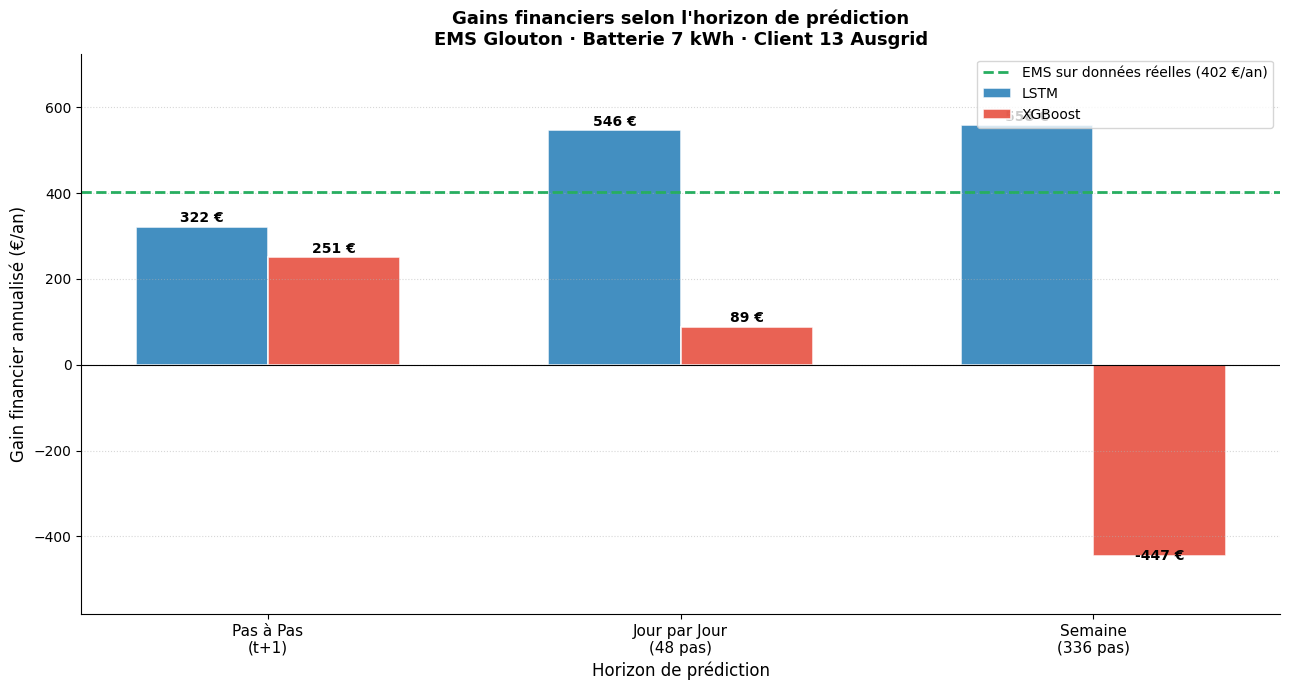

In [ ]:
# Bar plot — (gère les gains négatifs)
horizons_ax = ["Pas à Pas\n(t+1)", "Jour par Jour\n(48 pas)", "Semaine\n(336 pas)"]

gains_l = [gains_horizons['LSTM — Pas à Pas'],
           gains_horizons['LSTM — Jour par Jour'],
           gains_horizons['LSTM — Semaine']]
gains_x = [gains_horizons['XGBoost — Pas à Pas'],
           gains_horizons['XGBoost — Jour par Jour'],
           gains_horizons['XGBoost — Semaine']]

x = np.arange(len(horizons_ax)); width = 0.32

fig, ax = plt.subplots(figsize=(13, 7))
bars_l = ax.bar(x - width/2, gains_l, width, color='#2980b9', alpha=0.88, edgecolor='white', linewidth=1.2, label='LSTM')
bars_x = ax.bar(x + width/2, gains_x, width, color='#e74c3c', alpha=0.88, edgecolor='white', linewidth=1.2, label='XGBoost')
ax.axhline(gain_reel, color='#27ae60', linestyle='--', linewidth=2.0,
           label=f'EMS sur données réelles ({gain_reel:.0f} €/an)')

for bar in list(bars_l) + list(bars_x):
    h    = bar.get_height()
    ypos = h + (3 if h >= 0 else -15)
    ax.text(bar.get_x()+bar.get_width()/2, ypos, f'{h:.0f} €',
            ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_xlabel("Horizon de prédiction", fontsize=12)
ax.set_ylabel("Gain financier annualisé (€/an)", fontsize=12)
ax.set_title("Gains financiers selon l'horizon de prédiction\nEMS Glouton · Batterie 7 kWh · Client 13 Ausgrid",
             fontsize=13, fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(horizons_ax, fontsize=11)
ax.legend(fontsize=10, loc='upper right')
ax.grid(axis='y', linestyle=':', alpha=0.5); ax.spines[['top','right']].set_visible(False)

# CORRECTION : ylim dynamique — gère les valeurs négatives
all_gains = gains_l + gains_x + [gain_reel]
ymin = min(0, min(all_gains)) * 1.3
ymax = max(all_gains) * 1.3
ax.set_ylim(ymin, ymax)
if ymin < 0:
    ax.axhline(0, color='black', linewidth=0.8, linestyle='-')

plt.tight_layout(); plt.savefig("fig_gains_horizons.png", dpi=150, bbox_inches='tight'); plt.show()

## 11. Tableau de synthèse finale

In [ ]:
print("=" * 80)
print(f"{'SYNTHÈSE FINALE — IMPACT DE L\'HORIZON SUR L\'EMS':^80}")
print("=" * 80)
print(f"{'Combinaison':<32} {'MAE (kWh)':>10} {'RMSE':>8} {'Gain €/an':>10} {'vs Réel':>10}")
print("-" * 80)
for name in ems_results_horizons:
    mae_v, rmse_v = results_horizons[name]
    gain_v = gains_horizons[name]
    delta  = gain_v - gain_reel
    print(f"{name:<32} {mae_v:>10.3f} {rmse_v:>8.3f} {gain_v:>10.0f} {delta:>+10.0f}")
print("-" * 80)
print(f"{'Référence (données réelles)':<32} {'—':>10} {'—':>8} {gain_reel:>10.0f} {'0':>10}")
print("=" * 80)
print()
print("Lecture : 'vs Réel' = écart vs EMS omniscient (borne supérieure théorique).")
print("Un delta négatif = coût de l'erreur de prévision sur cet horizon.")

                SYNTHÈSE FINALE — IMPACT DE L'HORIZON SUR L'EMS                 
Combinaison                       MAE (kWh)     RMSE  Gain €/an    vs Réel
--------------------------------------------------------------------------------
LSTM — Pas à Pas                      0.125    0.233        322        -80
LSTM — Jour par Jour                  0.201    0.363        546       +144
LSTM — Semaine                        0.208    0.380        558       +156
XGBoost — Pas à Pas                   0.118    0.223        251       -151
XGBoost — Jour par Jour               0.210    0.328         89       -313
XGBoost — Semaine                     0.315    0.423       -447       -848
--------------------------------------------------------------------------------
Référence (données réelles)               —        —        402          0

Lecture : 'vs Réel' = écart vs EMS omniscient (borne supérieure théorique).
Un delta négatif = coût de l'erreur de prévision sur cet horizon.


## Annexe — Limitations techniques et tentatives non concluantes
- **LP sur 1 an** : trop coûteux en RAM (Google Colab ~12 GB) → limité à 1 jour
- **Autorégression LSTM** sur tout le jeu de test : trop lent → limité à n_test_lstm pas
- **XGBoost 300 arbres** : limite Colab (1000 → OOM)
- **Validation croisée TimeSeriesSplit** : fragments d'entraînement trop courts pour le LSTM